In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.width", 112)       # keeps printed tables tidy
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
print("Libraries ready")

Libraries ready


In [2]:
df = pd.read_csv("kidney_disease_dataset.csv")
print("File loaded successfully")
print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'kidney_disease_dataset.csv'

In [ ]:
print("Rows and columns:", df.shape)
print()
print("Column names:")
print(df.columns.tolist())
print()
print("Last 3 rows:")
print(df.tail(3))

Rows and columns: (20538, 43)

Column names:
['Age of the patient', 'Blood pressure (mm/Hg)', 'Specific gravity of urine', 'Albumin in urine', 'Sugar in urine', 'Red blood cells in urine', 'Pus cells in urine', 'Pus cell clumps in urine', 'Bacteria in urine', 'Random blood glucose level (mg/dl)', 'Blood urea (mg/dl)', 'Serum creatinine (mg/dl)', 'Sodium level (mEq/L)', 'Potassium level (mEq/L)', 'Hemoglobin level (gms)', 'Packed cell volume (%)', 'White blood cell count (cells/cumm)', 'Red blood cell count (millions/cumm)', 'Hypertension (yes/no)', 'Diabetes mellitus (yes/no)', 'Coronary artery disease (yes/no)', 'Appetite (good/poor)', 'Pedal edema (yes/no)', 'Anemia (yes/no)', 'Estimated Glomerular Filtration Rate (eGFR)', 'Urine protein-to-creatinine ratio', 'Urine output (ml/day)', 'Serum albumin level', 'Cholesterol level', 'Parathyroid hormone (PTH) level', 'Serum calcium level', 'Serum phosphate level', 'Family history of chronic kidney disease', 'Smoking status', 'Body Mass Ind

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20538 entries, 0 to 20537
Data columns (total 43 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   Age of the patient                           20538 non-null  int64  
 1   Blood pressure (mm/Hg)                       20538 non-null  int64  
 2   Specific gravity of urine                    20538 non-null  float64
 3   Albumin in urine                             20538 non-null  int64  
 4   Sugar in urine                               20538 non-null  int64  
 5   Red blood cells in urine                     20538 non-null  object 
 6   Pus cells in urine                           20538 non-null  object 
 7   Pus cell clumps in urine                     20538 non-null  object 
 8   Bacteria in urine                            20538 non-null  object 
 9   Random blood glucose level (mg/dl)           20538 non-null  int64  
 10

In [ ]:
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

print("Numeric columns    :", num_cols)
print("Categorical columns:", cat_cols)

Numeric columns    : ['Age of the patient', 'Blood pressure (mm/Hg)', 'Specific gravity of urine', 'Albumin in urine', 'Sugar in urine', 'Random blood glucose level (mg/dl)', 'Blood urea (mg/dl)', 'Serum creatinine (mg/dl)', 'Sodium level (mEq/L)', 'Potassium level (mEq/L)', 'Hemoglobin level (gms)', 'Packed cell volume (%)', 'White blood cell count (cells/cumm)', 'Red blood cell count (millions/cumm)', 'Estimated Glomerular Filtration Rate (eGFR)', 'Urine protein-to-creatinine ratio', 'Urine output (ml/day)', 'Serum albumin level', 'Cholesterol level', 'Parathyroid hormone (PTH) level', 'Serum calcium level', 'Serum phosphate level', 'Body Mass Index (BMI)', 'Duration of diabetes mellitus (years)', 'Duration of hypertension (years)', 'Cystatin C level', 'C-reactive protein (CRP) level', 'Interleukin-6 (IL-6) level']
Categorical columns: ['Red blood cells in urine', 'Pus cells in urine', 'Pus cell clumps in urine', 'Bacteria in urine', 'Hypertension (yes/no)', 'Diabetes mellitus (yes/n

In [ ]:
print(df.describe().T.round(2))

                                               count     mean      std     min      25%      50%       75%  \
Age of the patient                           20538.0    47.48    24.94     5.0    26.00    47.00     69.00   
Blood pressure (mm/Hg)                       20538.0   130.35    29.06    80.0   105.00   131.00    156.00   
Specific gravity of urine                    20538.0     1.02     0.01     1.0     1.01     1.01      1.02   
Albumin in urine                             20538.0     2.50     1.70     0.0     1.00     3.00      4.00   
Sugar in urine                               20538.0     2.49     1.70     0.0     1.00     2.00      4.00   
Random blood glucose level (mg/dl)           20538.0   284.63   124.63    70.0   176.00   284.50    393.00   
Blood urea (mg/dl)                           20538.0   104.09    55.73     7.0    55.86   104.40    152.48   
Serum creatinine (mg/dl)                     20538.0     7.78     4.18     0.5     4.20     7.78     11.43   
Sodium lev

In [ ]:
missing = df.isna().sum()
missing_pct = (df.isna().mean() * 100).round(1)

report = pd.DataFrame({"missing": missing, "percent": missing_pct})
print(report[report["missing"] > 0])

Empty DataFrame
Columns: [missing, percent]
Index: []


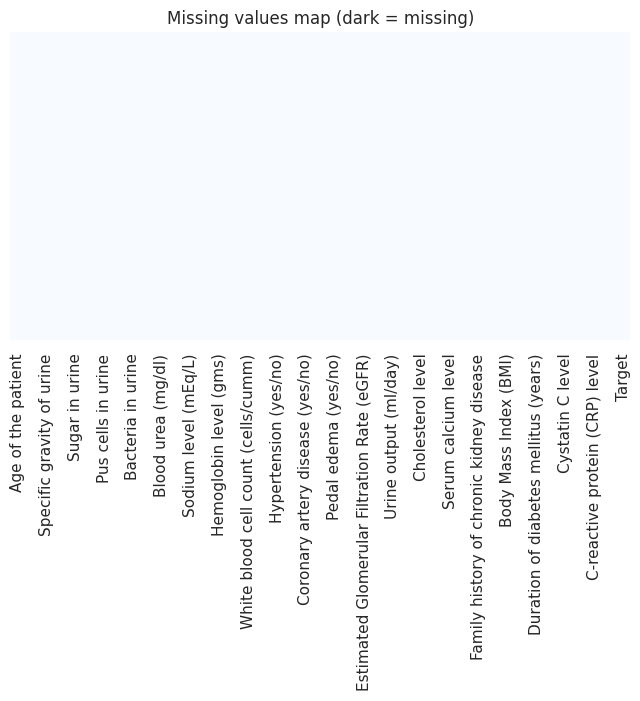

In [ ]:
plt.figure(figsize=(8, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="Blues")
plt.title("Missing values map (dark = missing)")
plt.show()

In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print()
print(df[df.duplicated(keep=False)])

Duplicate rows: 0

Empty DataFrame
Columns: [Age of the patient, Blood pressure (mm/Hg), Specific gravity of urine, Albumin in urine, Sugar in urine, Red blood cells in urine, Pus cells in urine, Pus cell clumps in urine, Bacteria in urine, Random blood glucose level (mg/dl), Blood urea (mg/dl), Serum creatinine (mg/dl), Sodium level (mEq/L), Potassium level (mEq/L), Hemoglobin level (gms), Packed cell volume (%), White blood cell count (cells/cumm), Red blood cell count (millions/cumm), Hypertension (yes/no), Diabetes mellitus (yes/no), Coronary artery disease (yes/no), Appetite (good/poor), Pedal edema (yes/no), Anemia (yes/no), Estimated Glomerular Filtration Rate (eGFR), Urine protein-to-creatinine ratio, Urine output (ml/day), Serum albumin level, Cholesterol level, Parathyroid hormone (PTH) level, Serum calcium level, Serum phosphate level, Family history of chronic kidney disease, Smoking status, Body Mass Index (BMI), Physical activity level, Duration of diabetes mellitus (year

In [ ]:
print(df["Red blood cells in urine"].value_counts())

Red blood cells in urine
normal      10272
abnormal    10266
Name: count, dtype: int64


In [ ]:
print(df["Target"].value_counts())

print("\nTarget percentage:")
print(
    (df["Target"].value_counts(normalize=True) * 100)
    .round(2)
)

Target
No_Disease        16432
Low_Risk           2054
Moderate_Risk       821
High_Risk           821
Severe_Disease      410
Name: count, dtype: int64

Target percentage:
Target
No_Disease        80.01
Low_Risk          10.00
Moderate_Risk      4.00
High_Risk          4.00
Severe_Disease     2.00
Name: proportion, dtype: float64


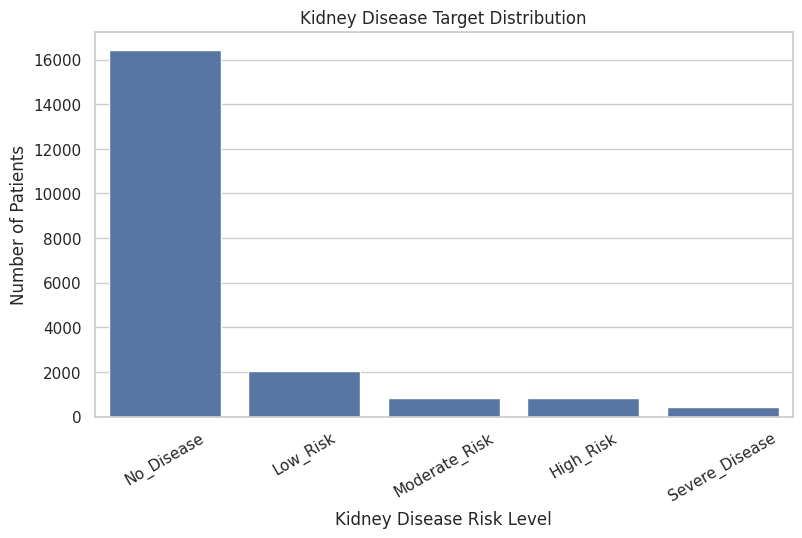

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Target",
    order=df["Target"].value_counts().index
)

plt.title("Kidney Disease Target Distribution")
plt.xticks(rotation=30)
plt.xlabel("Kidney Disease Risk Level")
plt.ylabel("Number of Patients")

plt.show()

In [ ]:
for col in cat_cols:
    print("\n" + "=" * 60)
    print(col)
    print(df[col].value_counts(dropna=False))


Red blood cells in urine
Red blood cells in urine
normal      10272
abnormal    10266
Name: count, dtype: int64

Pus cells in urine
Pus cells in urine
abnormal    10274
normal      10264
Name: count, dtype: int64

Pus cell clumps in urine
Pus cell clumps in urine
present        10298
not present    10240
Name: count, dtype: int64

Bacteria in urine
Bacteria in urine
not present    10353
present        10185
Name: count, dtype: int64

Hypertension (yes/no)
Hypertension (yes/no)
yes    10311
no     10227
Name: count, dtype: int64

Diabetes mellitus (yes/no)
Diabetes mellitus (yes/no)
no     10300
yes    10238
Name: count, dtype: int64

Coronary artery disease (yes/no)
Coronary artery disease (yes/no)
yes    10303
no     10235
Name: count, dtype: int64

Appetite (good/poor)
Appetite (good/poor)
good    10384
poor    10154
Name: count, dtype: int64

Pedal edema (yes/no)
Pedal edema (yes/no)
yes    10287
no     10251
Name: count, dtype: int64

Anemia (yes/no)
Anemia (yes/no)
yes    10402
n

In [ ]:
for col in num_cols:
    print(
        f"{col:50s} "
        f"Min={df[col].min():.2f} "
        f"Max={df[col].max():.2f}"
    )

Age of the patient                                 Min=5.00 Max=90.00
Blood pressure (mm/Hg)                             Min=80.00 Max=180.00
Specific gravity of urine                          Min=1.00 Max=1.02
Albumin in urine                                   Min=0.00 Max=5.00
Sugar in urine                                     Min=0.00 Max=5.00
Random blood glucose level (mg/dl)                 Min=70.00 Max=500.00
Blood urea (mg/dl)                                 Min=7.00 Max=199.99
Serum creatinine (mg/dl)                           Min=0.50 Max=15.00
Sodium level (mEq/L)                               Min=120.00 Max=150.00
Potassium level (mEq/L)                            Min=3.50 Max=6.50
Hemoglobin level (gms)                             Min=6.00 Max=18.00
Packed cell volume (%)                             Min=20.00 Max=55.00
White blood cell count (cells/cumm)                Min=3000.00 Max=15000.00
Red blood cell count (millions/cumm)               Min=2.50 Max=6.00
Estimated 

In [ ]:
def iqr_limits(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr

    return low, high


for col in num_cols:
    low, high = iqr_limits(df[col].dropna())

    outliers = (
        (df[col] < low) |
        (df[col] > high)
    ).sum()

    print(
        f"{col:50s} "
        f"Range=({low:.2f}, {high:.2f}) "
        f"Outliers={outliers}"
    )

Age of the patient                                 Range=(-38.50, 133.50) Outliers=0
Blood pressure (mm/Hg)                             Range=(28.50, 232.50) Outliers=0
Specific gravity of urine                          Range=(0.99, 1.04) Outliers=0
Albumin in urine                                   Range=(-3.50, 8.50) Outliers=0
Sugar in urine                                     Range=(-3.50, 8.50) Outliers=0
Random blood glucose level (mg/dl)                 Range=(-149.50, 718.50) Outliers=0
Blood urea (mg/dl)                                 Range=(-89.06, 297.40) Outliers=0
Serum creatinine (mg/dl)                           Range=(-6.64, 22.27) Outliers=0
Sodium level (mEq/L)                               Range=(105.00, 165.17) Outliers=0
Potassium level (mEq/L)                            Range=(1.95, 8.03) Outliers=0
Hemoglobin level (gms)                             Range=(0.15, 23.75) Outliers=0
Packed cell volume (%)                             Range=(-0.50, 75.50) Outliers=0
W

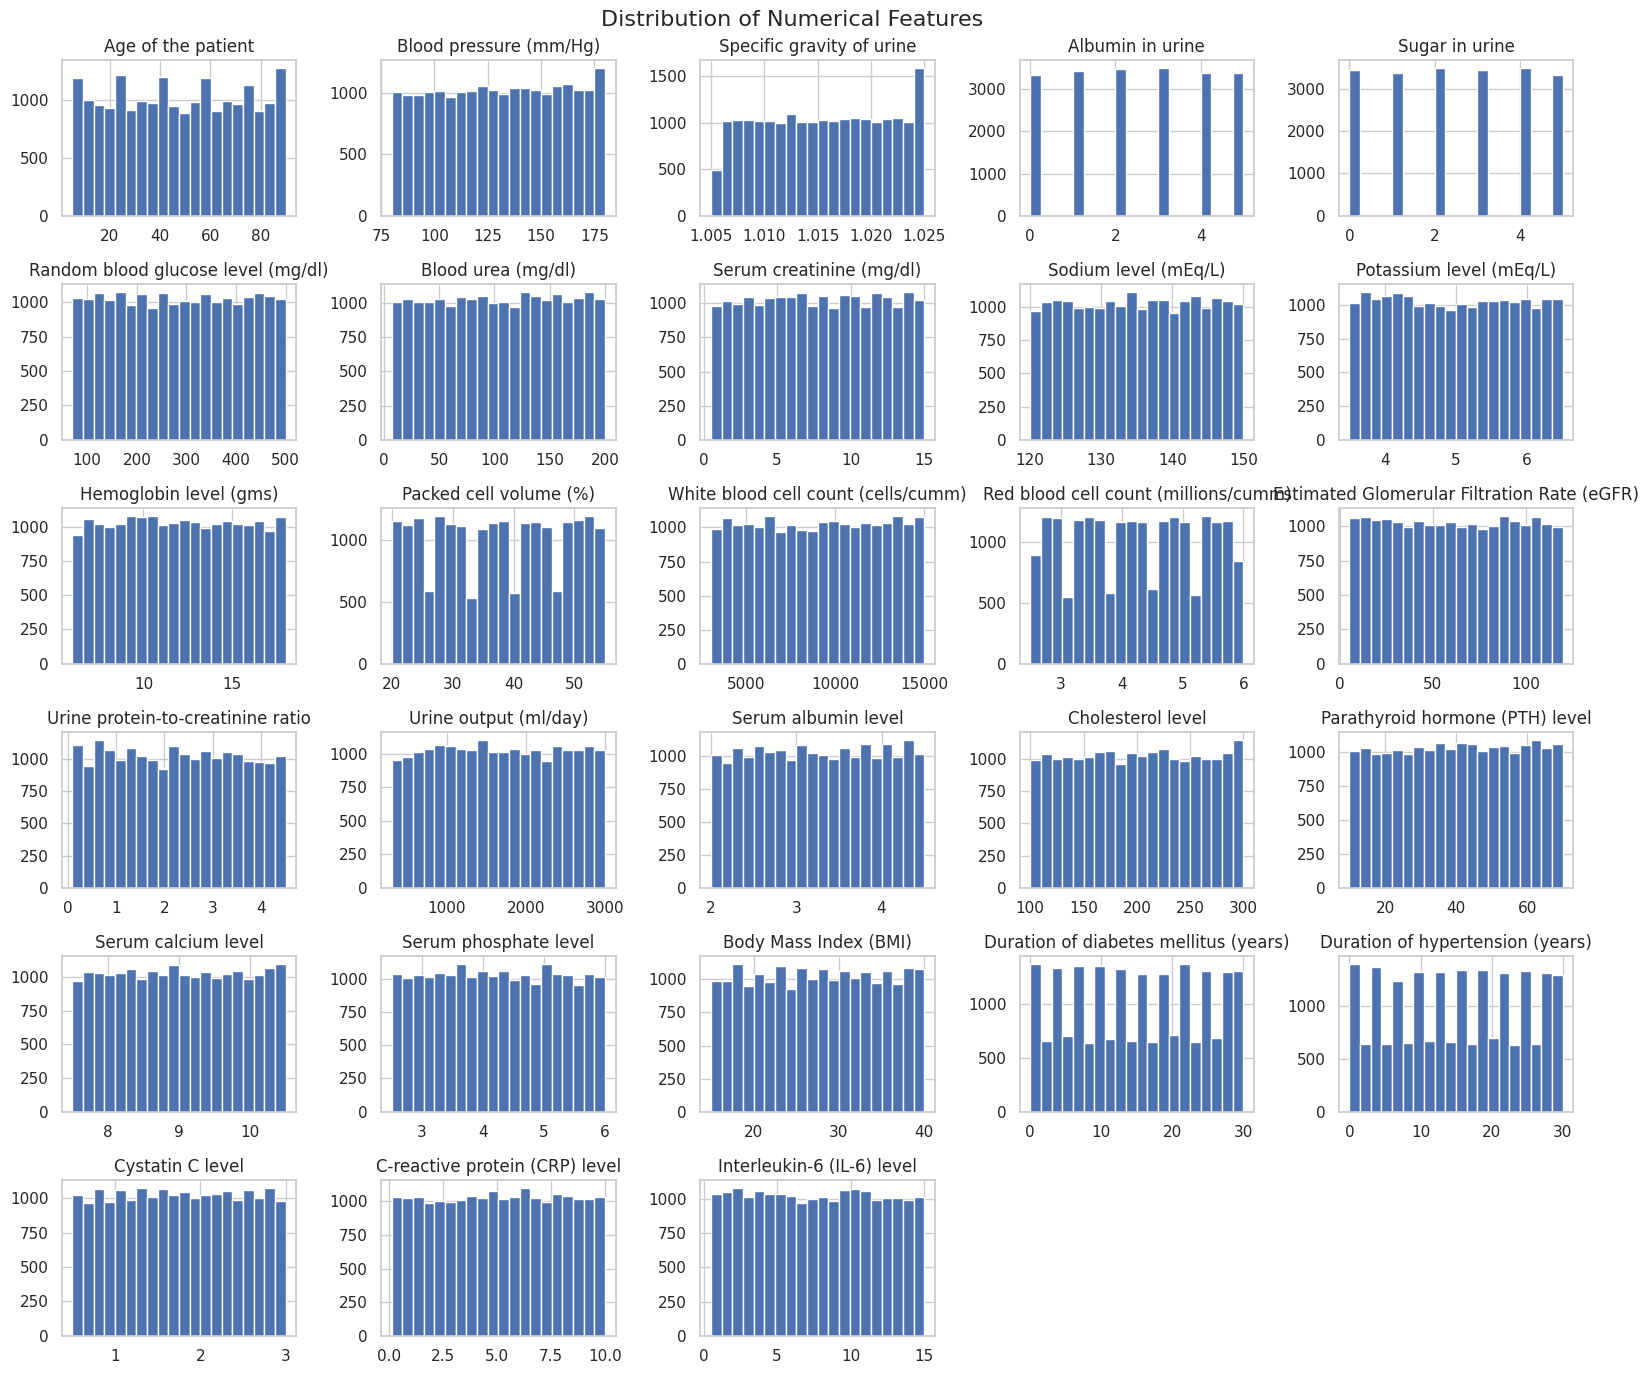

In [ ]:
df[num_cols].hist(
    figsize=(16, 14),
    bins=20
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

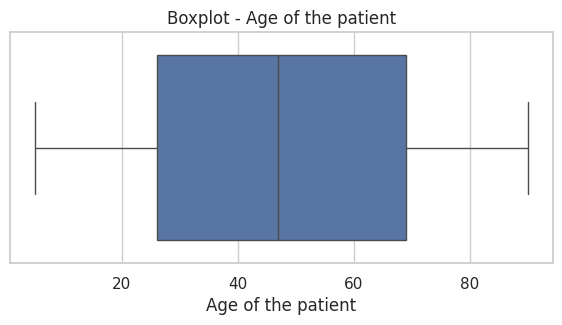

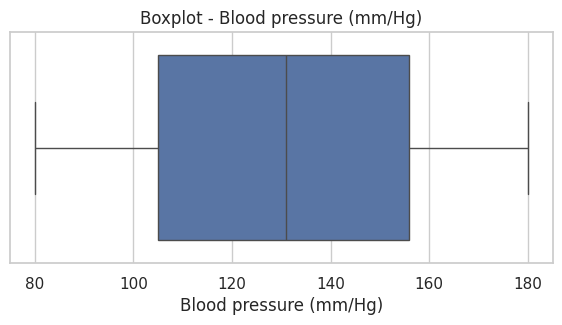

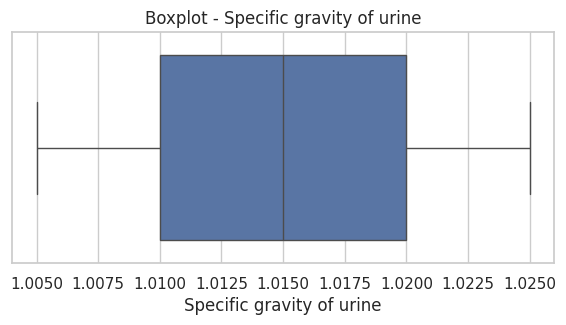

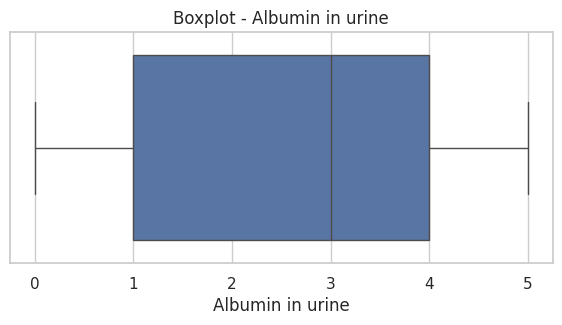

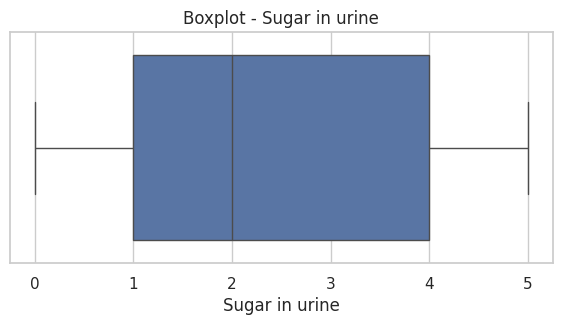

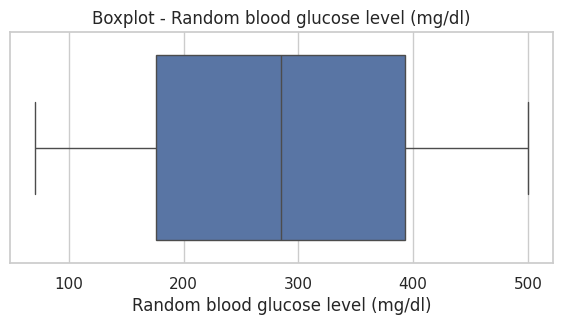

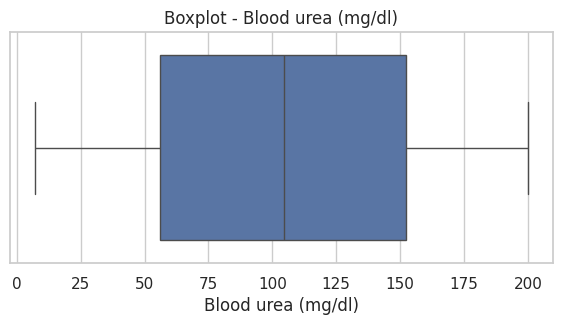

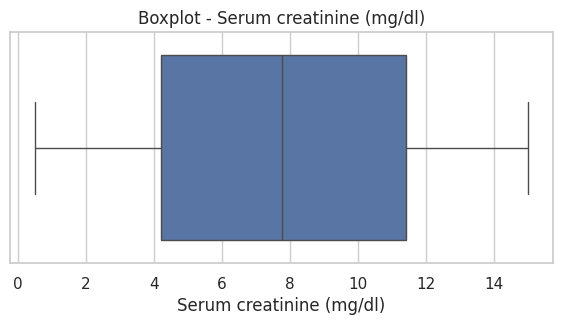

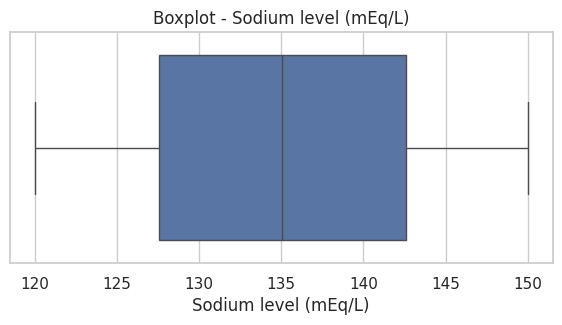

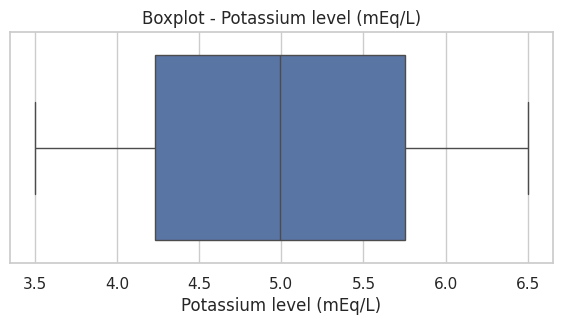

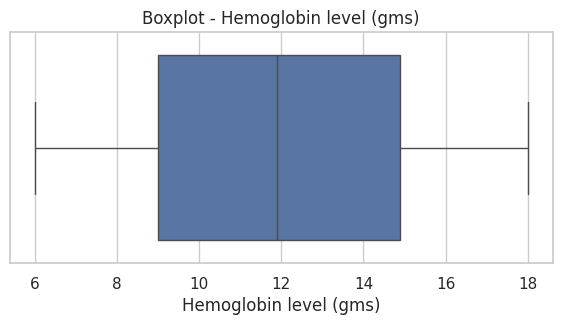

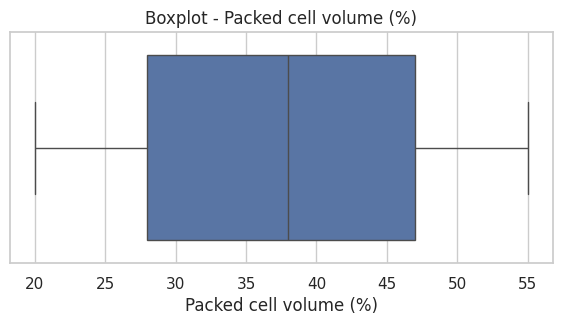

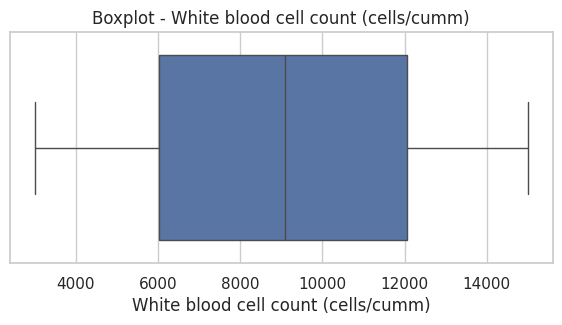

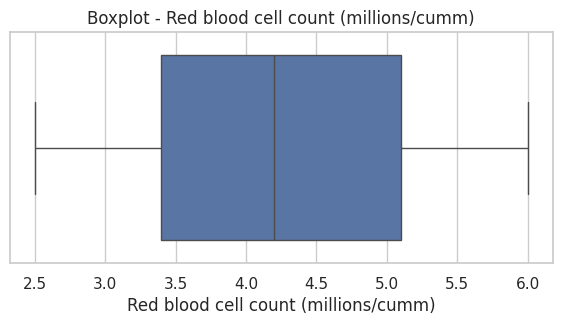

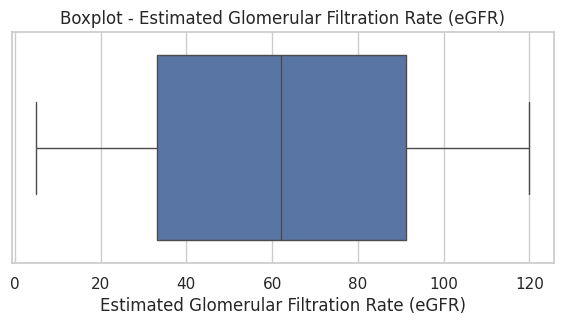

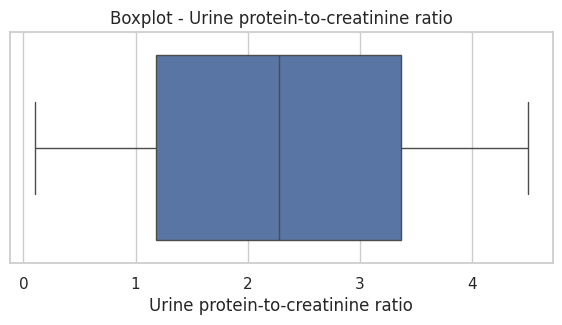

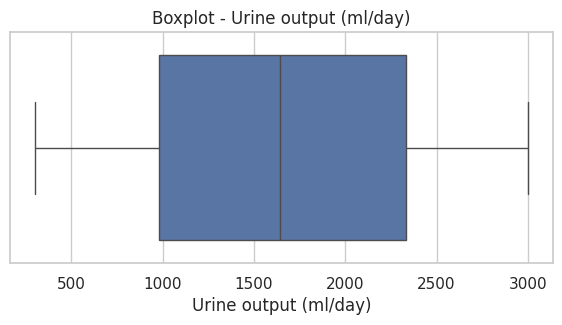

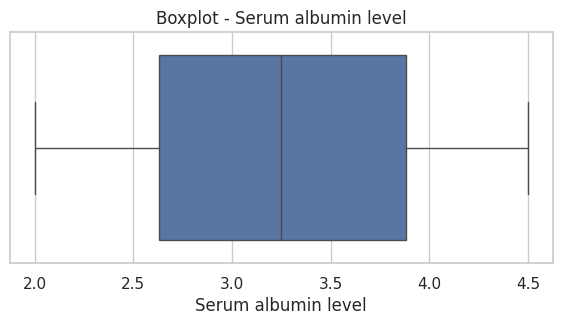

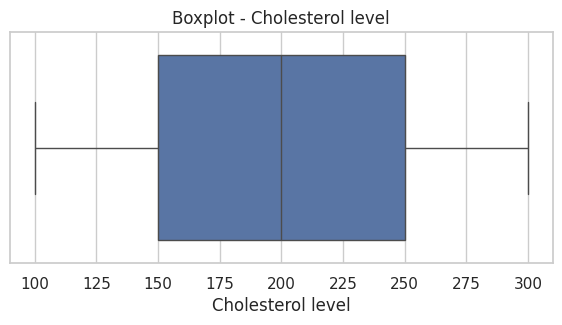

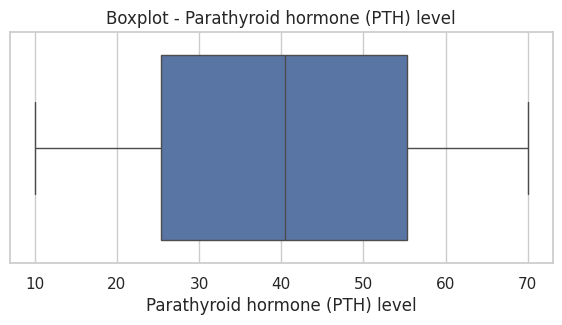

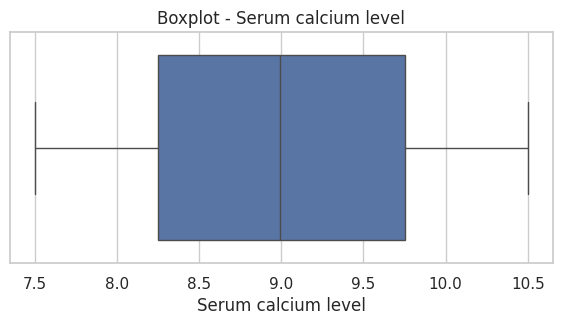

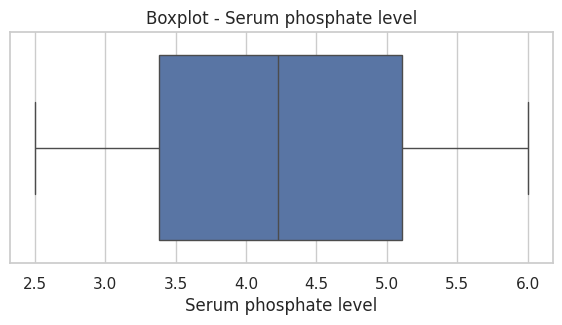

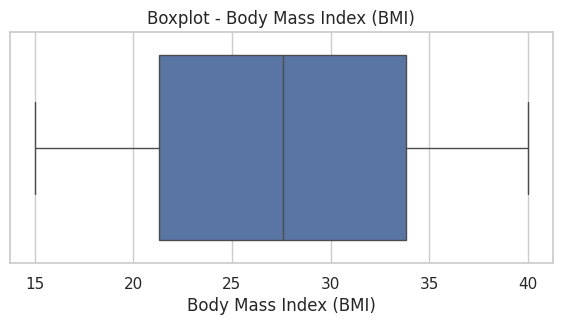

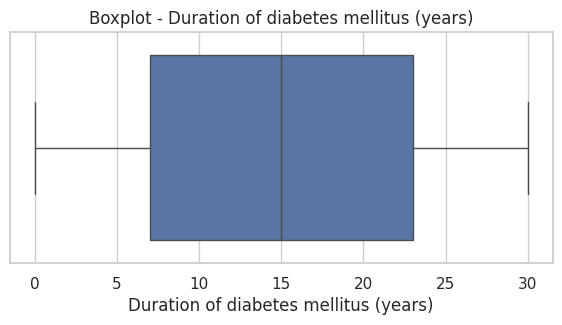

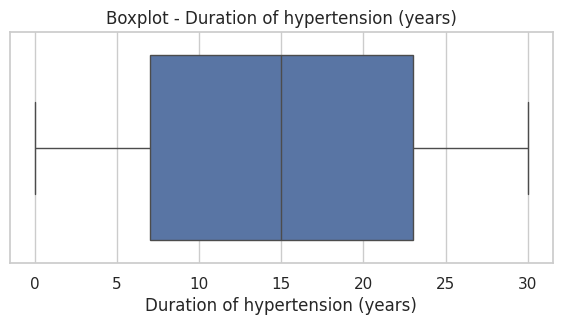

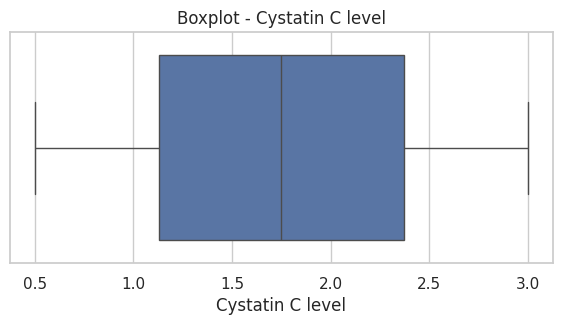

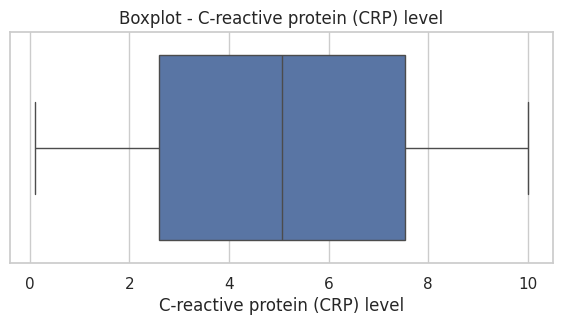

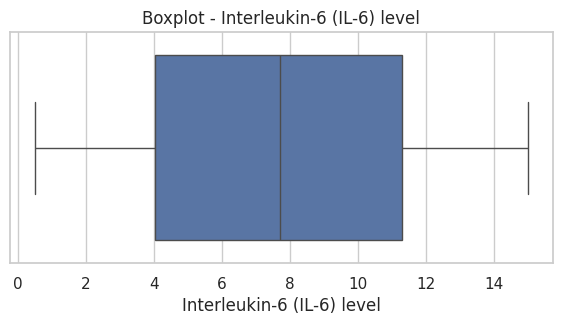

In [ ]:
for col in num_cols:
    plt.figure(figsize=(7, 3))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot - {col}")
    plt.show()

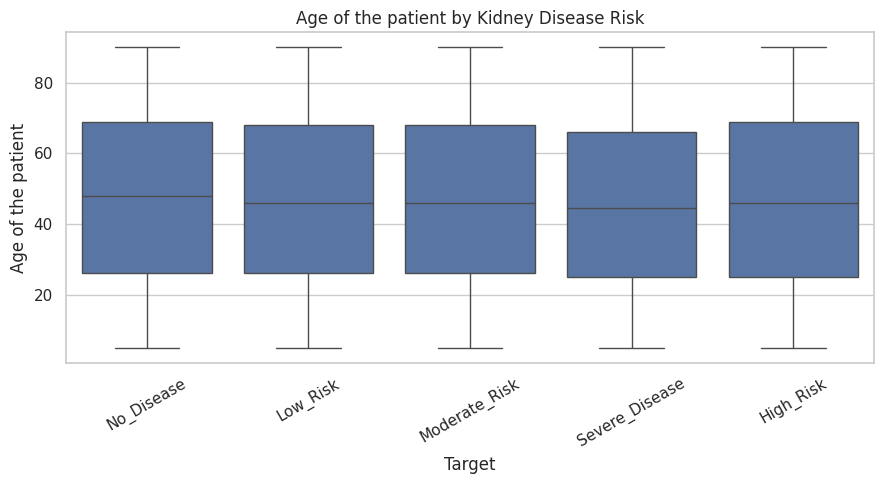

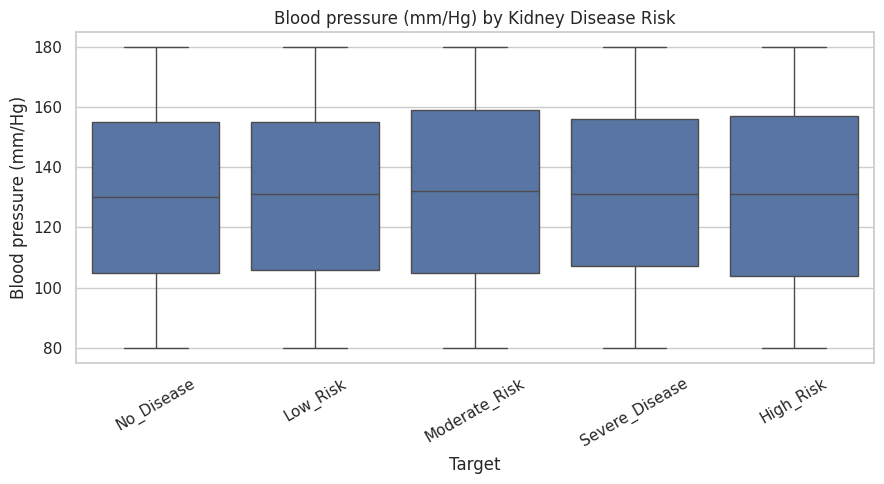

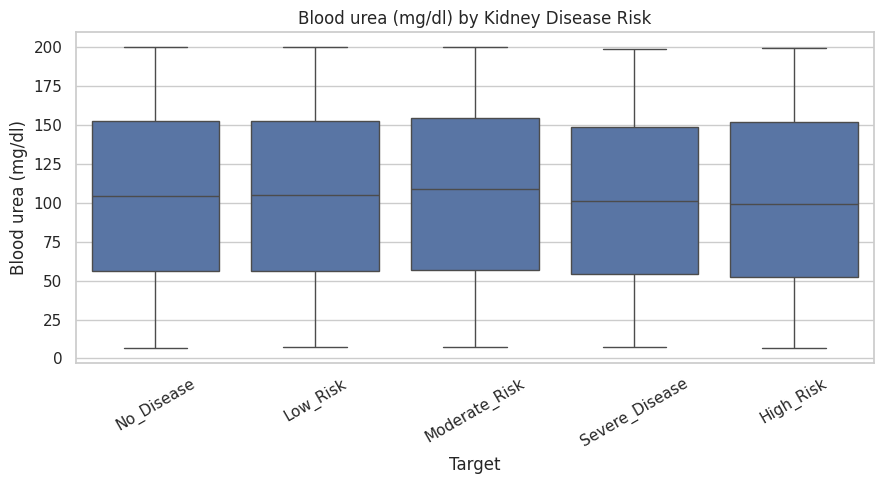

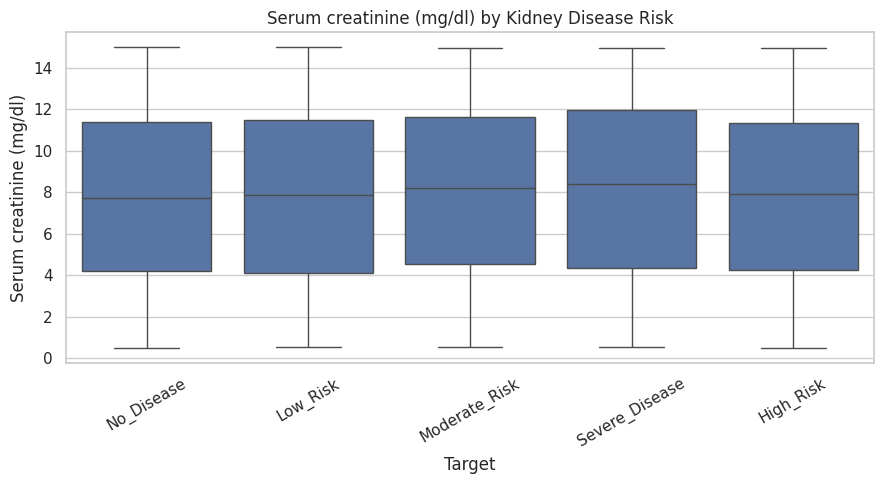

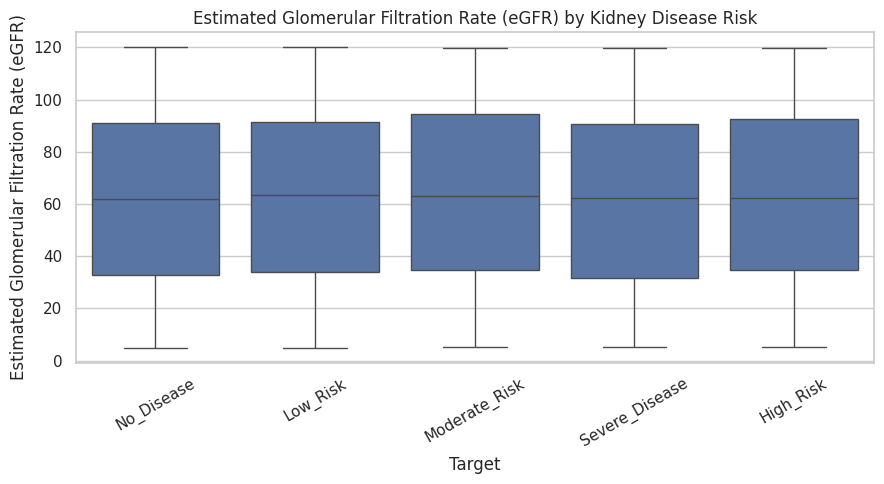

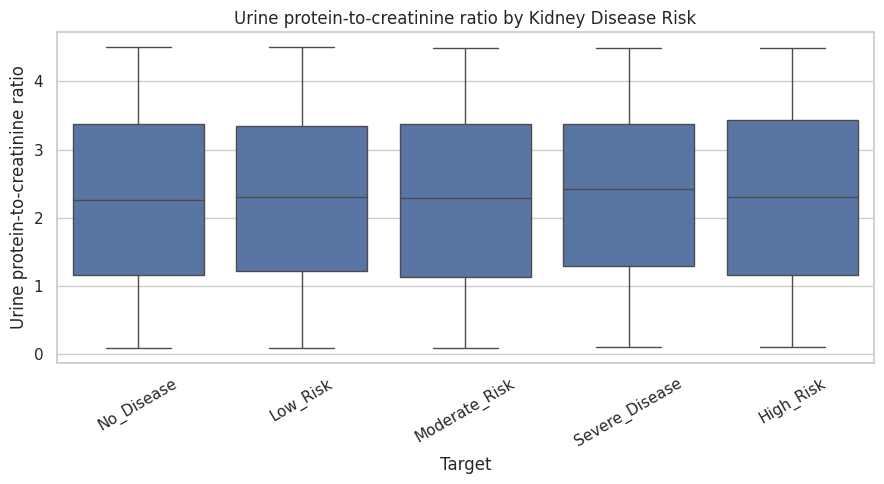

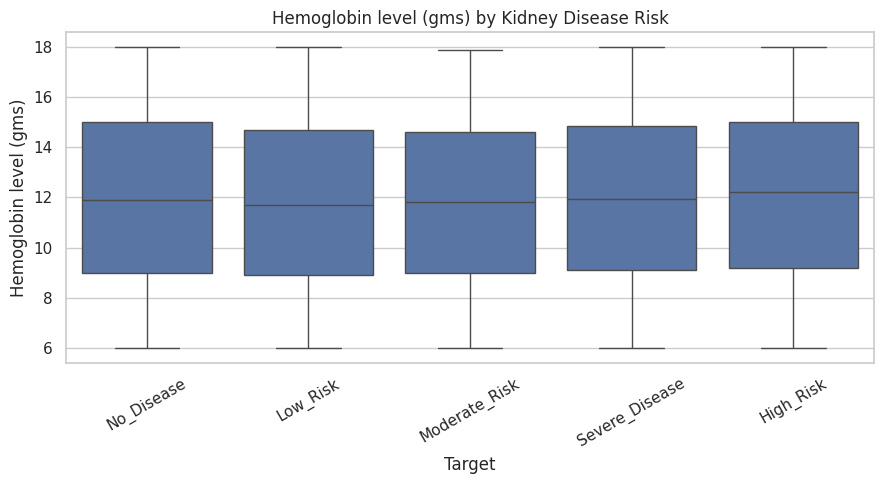

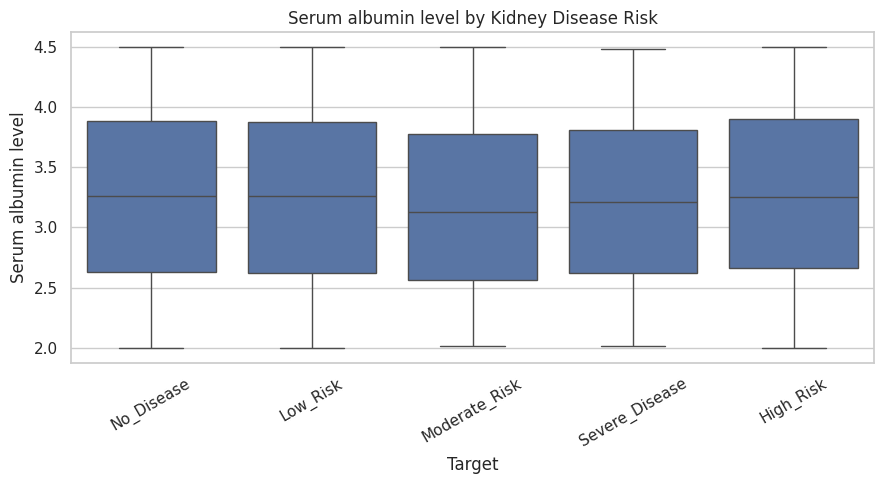

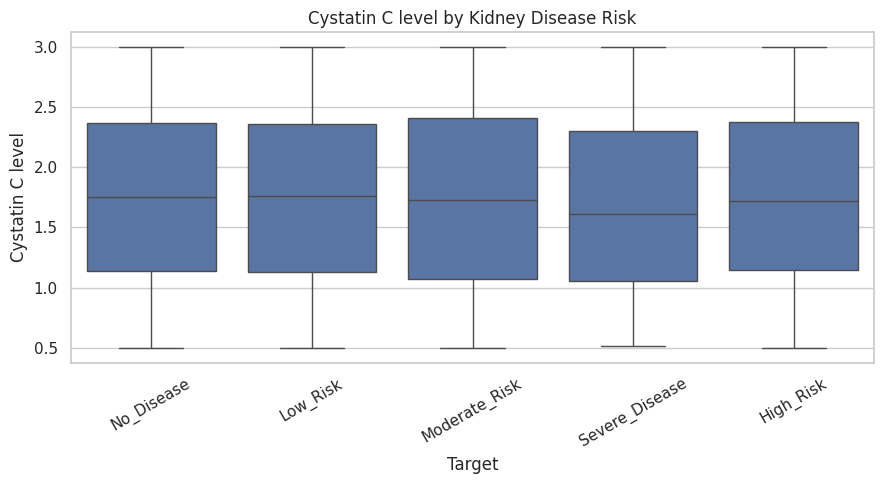

In [ ]:
important_num = [
    "Age of the patient",
    "Blood pressure (mm/Hg)",
    "Blood urea (mg/dl)",
    "Serum creatinine (mg/dl)",
    "Estimated Glomerular Filtration Rate (eGFR)",
    "Urine protein-to-creatinine ratio",
    "Hemoglobin level (gms)",
    "Serum albumin level",
    "Cystatin C level"
]

for col in important_num:

    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=df,
        x="Target",
        y=col
    )

    plt.title(f"{col} by Kidney Disease Risk")
    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.show()

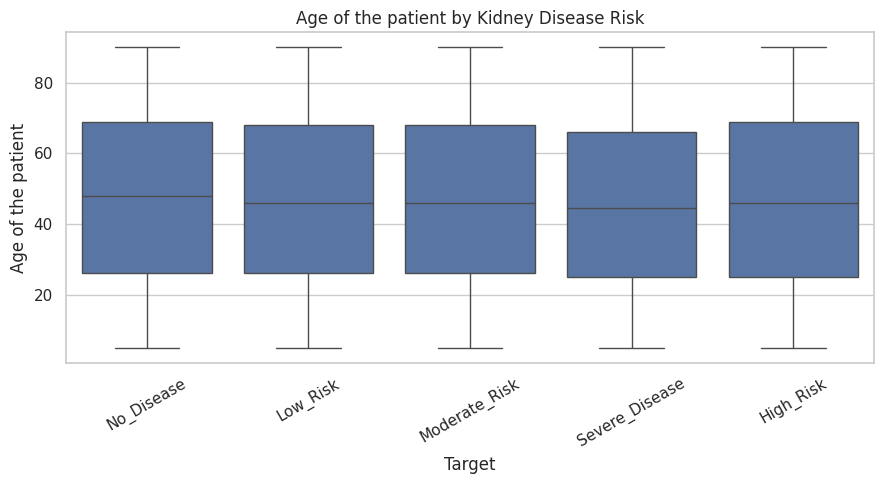

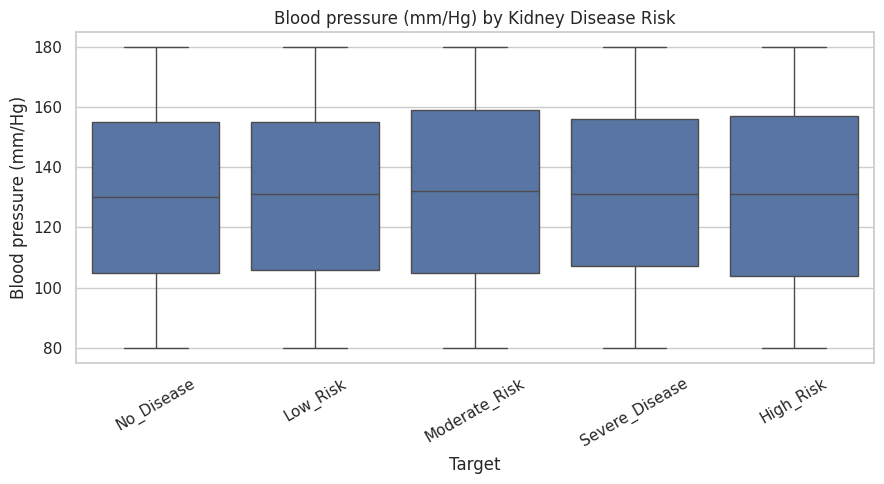

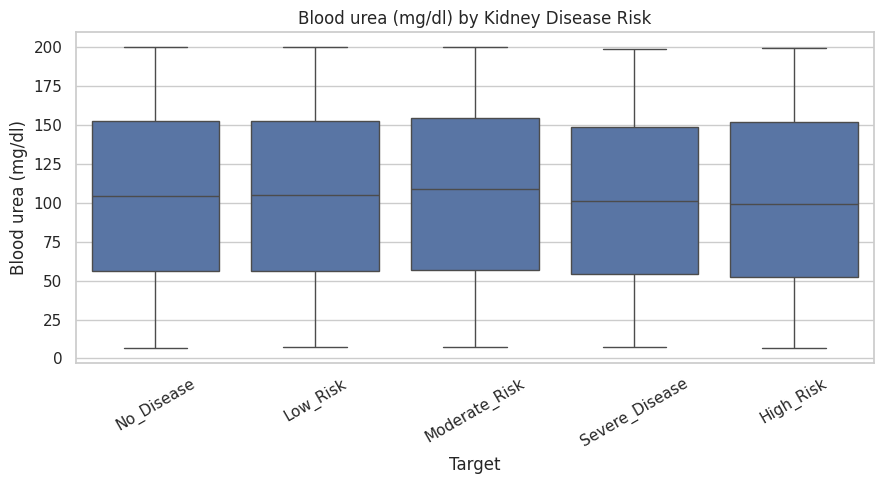

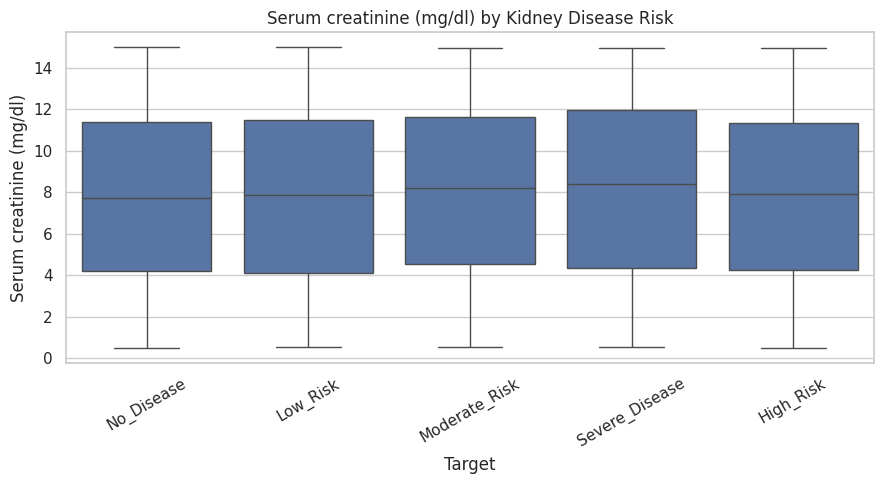

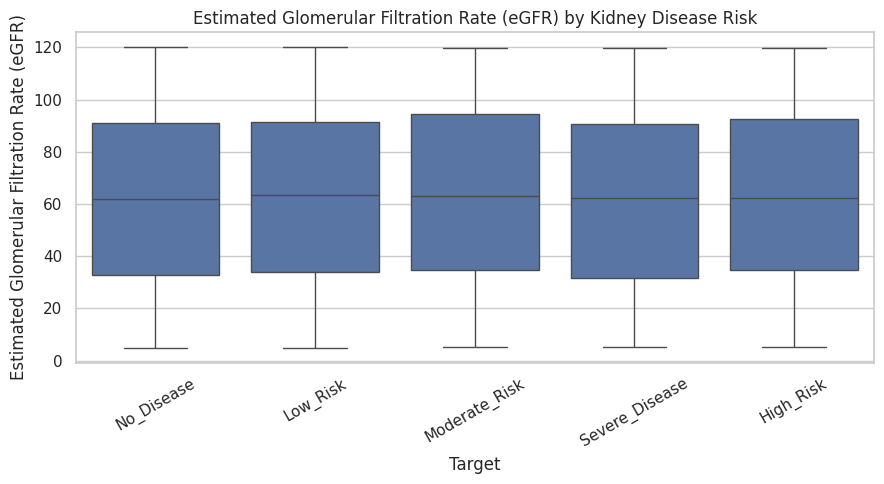

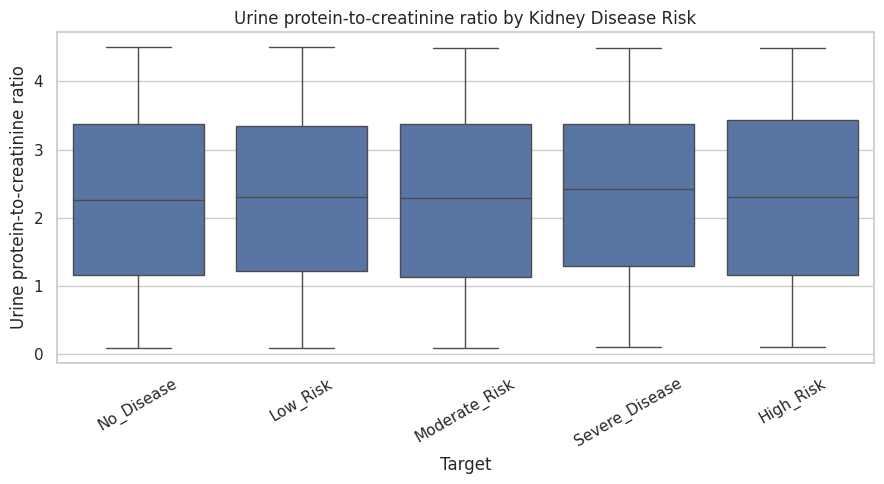

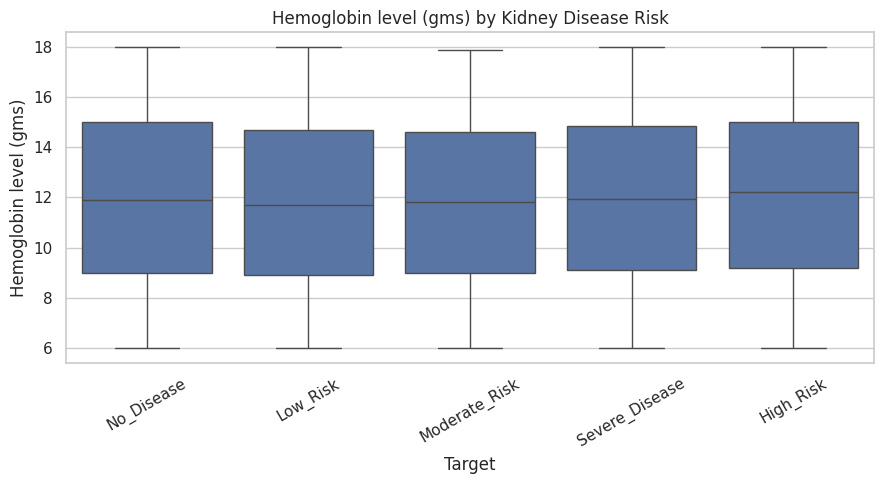

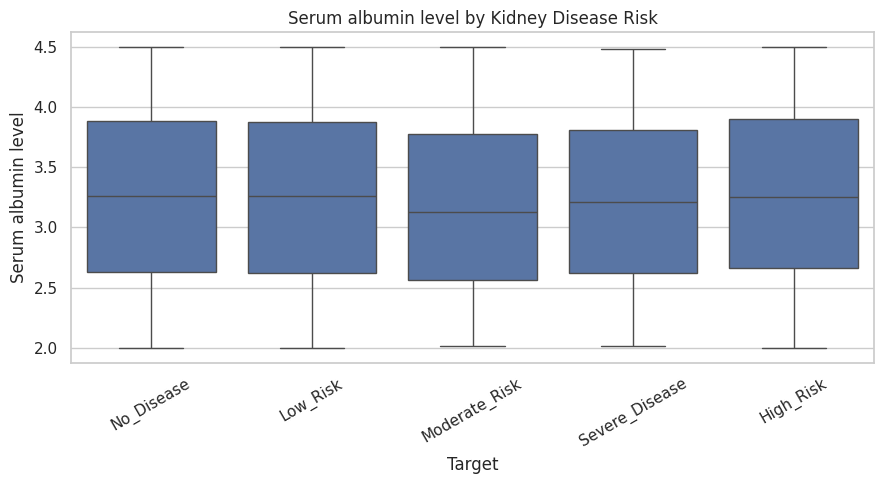

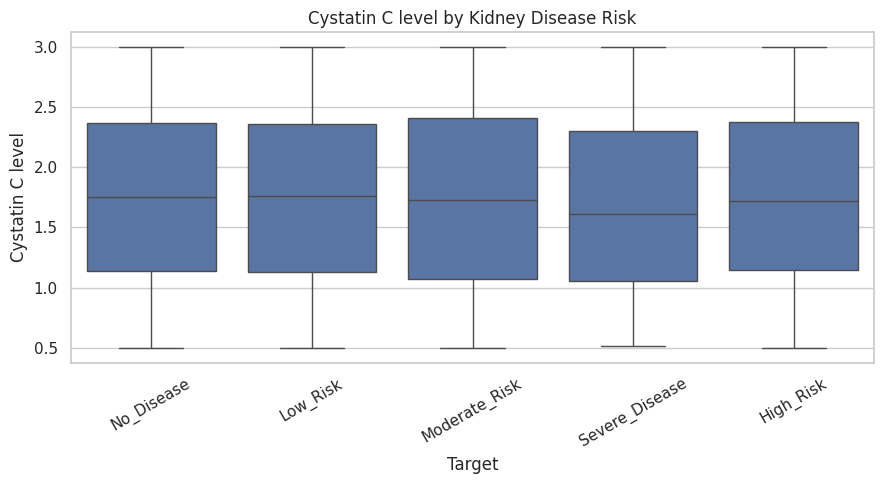

In [ ]:
important_num = [
    "Age of the patient",
    "Blood pressure (mm/Hg)",
    "Blood urea (mg/dl)",
    "Serum creatinine (mg/dl)",
    "Estimated Glomerular Filtration Rate (eGFR)",
    "Urine protein-to-creatinine ratio",
    "Hemoglobin level (gms)",
    "Serum albumin level",
    "Cystatin C level"
]

for col in important_num:

    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=df,
        x="Target",
        y=col
    )

    plt.title(f"{col} by Kidney Disease Risk")
    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.show()

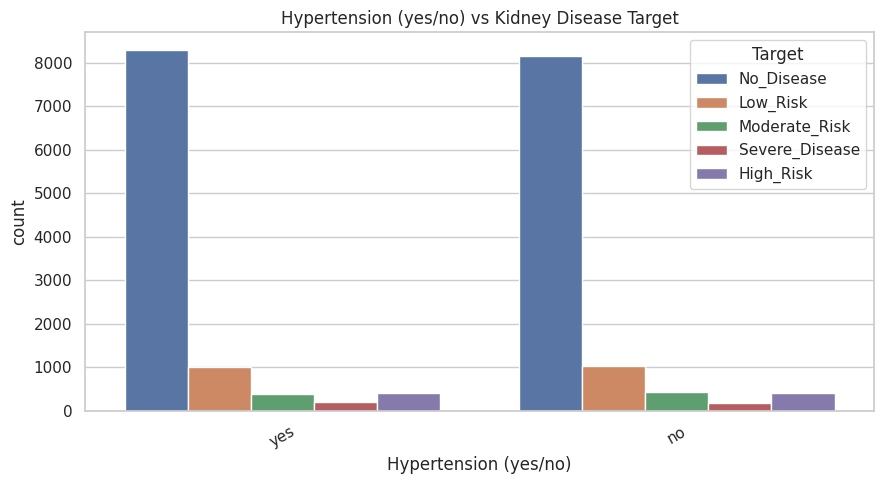

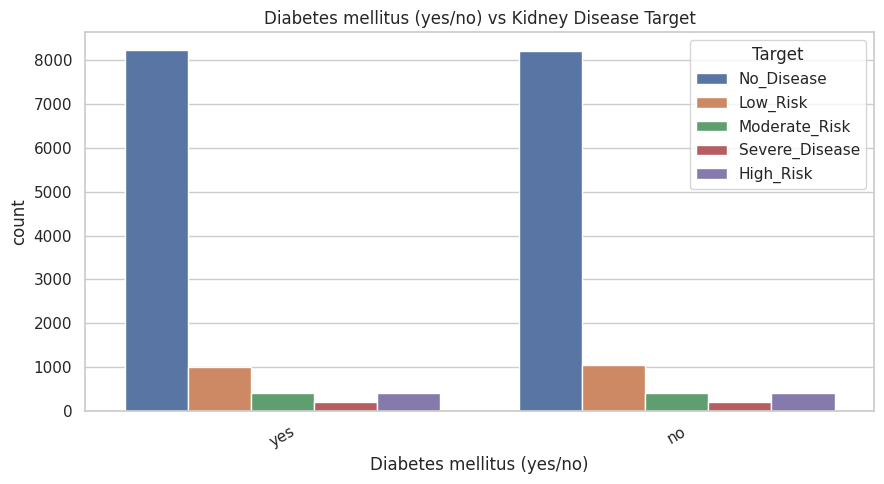

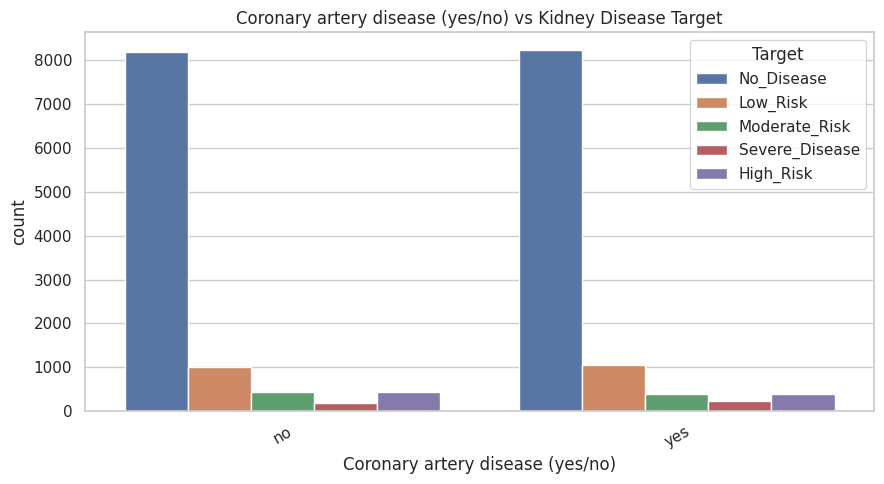

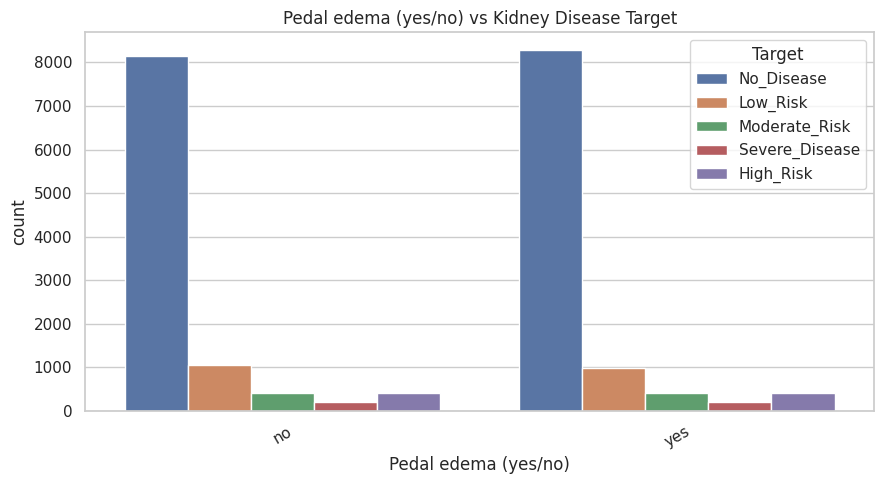

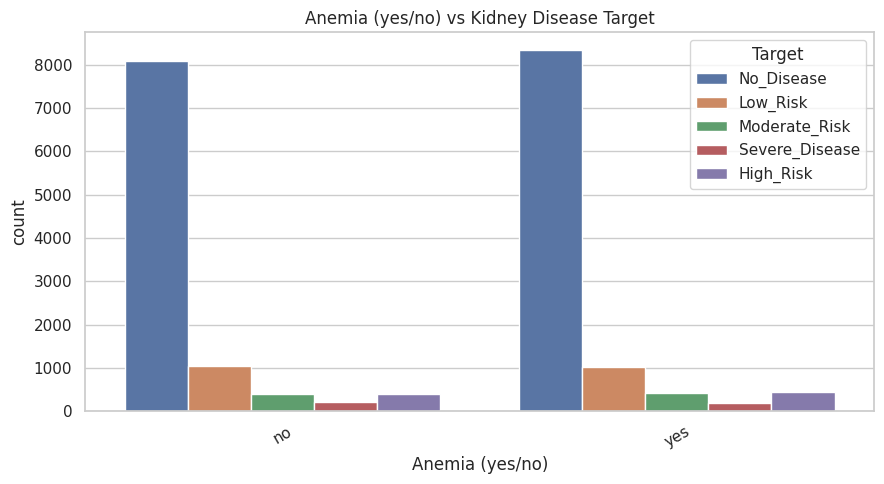

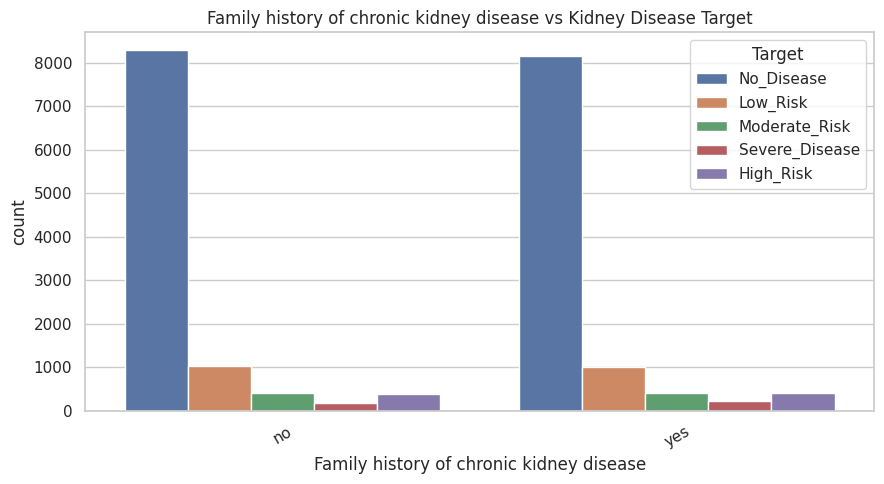

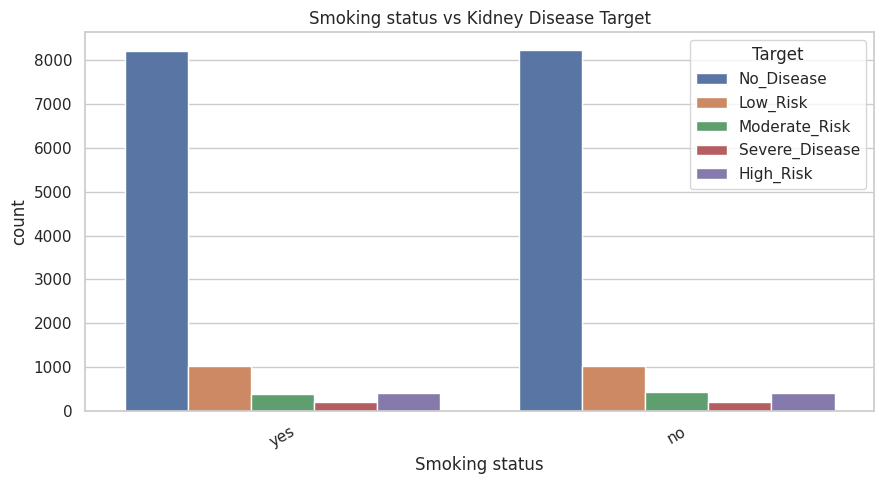

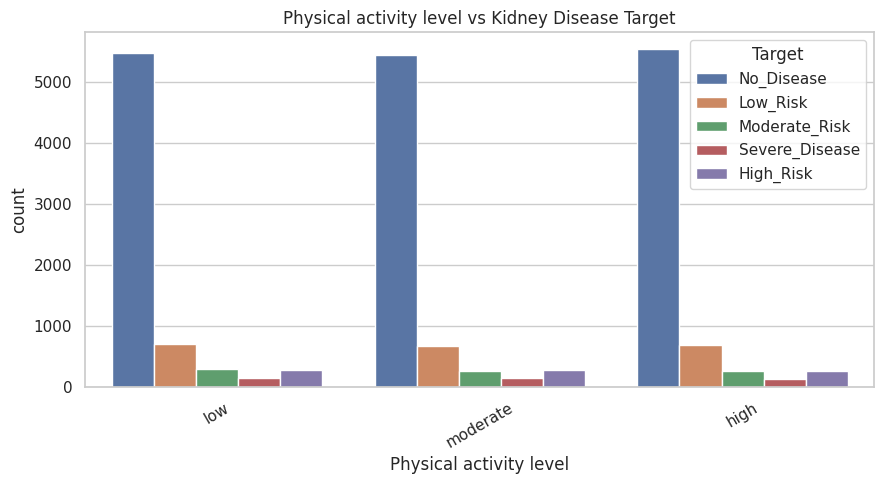

In [ ]:
important_cat = [
    "Hypertension (yes/no)",
    "Diabetes mellitus (yes/no)",
    "Coronary artery disease (yes/no)",
    "Pedal edema (yes/no)",
    "Anemia (yes/no)",
    "Family history of chronic kidney disease",
    "Smoking status",
    "Physical activity level"
]

for col in important_cat:

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df,
        x=col,
        hue="Target"
    )

    plt.title(f"{col} vs Kidney Disease Target")
    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.show()

In [ ]:
risk_summary = df.groupby("Target").agg(
    Patients=("Target", "count"),
    Avg_Age=("Age of the patient", "mean"),
    Avg_BP=("Blood pressure (mm/Hg)", "mean"),
    Avg_Urea=("Blood urea (mg/dl)", "mean"),
    Avg_Creatinine=("Serum creatinine (mg/dl)", "mean"),
    Avg_eGFR=("Estimated Glomerular Filtration Rate (eGFR)", "mean"),
    Avg_Hemoglobin=("Hemoglobin level (gms)", "mean"),
    Avg_BMI=("Body Mass Index (BMI)", "mean")
).round(2)

print(risk_summary)

                Patients  Avg_Age  Avg_BP  Avg_Urea  Avg_Creatinine  Avg_eGFR  Avg_Hemoglobin  Avg_BMI
Target                                                                                                
High_Risk            821    46.31  130.69    101.68            7.78     63.06           12.07    27.40
Low_Risk            2054    47.10  130.53    104.31            7.82     63.07           11.83    27.59
Moderate_Risk        821    46.43  131.60    105.98            8.03     64.05           11.83    27.69
No_Disease         16432    47.67  130.23    104.15            7.76     62.02           11.98    27.53
Severe_Disease       410    46.30  131.20    101.90            8.12     61.17           11.92    27.81


In [ ]:
print(
    pd.crosstab(
        df["Hypertension (yes/no)"],
        df["Target"]
    )
)

Target                 High_Risk  Low_Risk  Moderate_Risk  No_Disease  Severe_Disease
Hypertension (yes/no)                                                                
no                           417      1035            432        8149             194
yes                          404      1019            389        8283             216


In [ ]:
print(
    (
        pd.crosstab(
            df["Hypertension (yes/no)"],
            df["Target"],
            normalize="index"
        ) * 100
    ).round(2)
)

Target                 High_Risk  Low_Risk  Moderate_Risk  No_Disease  Severe_Disease
Hypertension (yes/no)                                                                
no                          4.08     10.12           4.22       79.68            1.90
yes                         3.92      9.88           3.77       80.33            2.09


In [ ]:
corr = df[num_cols].corr()

print(corr.round(2))

                                             Age of the patient  Blood pressure (mm/Hg)  \
Age of the patient                                         1.00                   -0.00   
Blood pressure (mm/Hg)                                    -0.00                    1.00   
Specific gravity of urine                                 -0.00                   -0.01   
Albumin in urine                                          -0.00                   -0.01   
Sugar in urine                                             0.01                    0.00   
Random blood glucose level (mg/dl)                        -0.01                   -0.00   
Blood urea (mg/dl)                                         0.01                   -0.00   
Serum creatinine (mg/dl)                                  -0.01                   -0.01   
Sodium level (mEq/L)                                       0.01                   -0.00   
Potassium level (mEq/L)                                    0.00                    0.00   

In [ ]:
target_map = {
    "No_Disease": 0,
    "Low_Risk": 1,
    "Moderate_Risk": 2,
    "High_Risk": 3,
    "Severe_Disease": 4
}

df["Target_Code"] = df["Target"].map(target_map)

target_corr = (
    df[num_cols]
    .corrwith(df["Target_Code"])
    .sort_values(key=abs, ascending=False)
)

print(target_corr.round(3))

Specific gravity of urine                     -0.017
Age of the patient                            -0.016
Serum creatinine (mg/dl)                       0.014
Serum albumin level                           -0.012
White blood cell count (cells/cumm)            0.010
Albumin in urine                               0.009
Blood pressure (mm/Hg)                         0.009
Cystatin C level                              -0.009
Estimated Glomerular Filtration Rate (eGFR)    0.008
Sugar in urine                                 0.008
Potassium level (mEq/L)                       -0.007
Blood urea (mg/dl)                            -0.006
Duration of diabetes mellitus (years)         -0.006
Urine output (ml/day)                          0.006
Duration of hypertension (years)               0.005
Urine protein-to-creatinine ratio              0.005
Hemoglobin level (gms)                        -0.004
Packed cell volume (%)                         0.003
Sodium level (mEq/L)                          

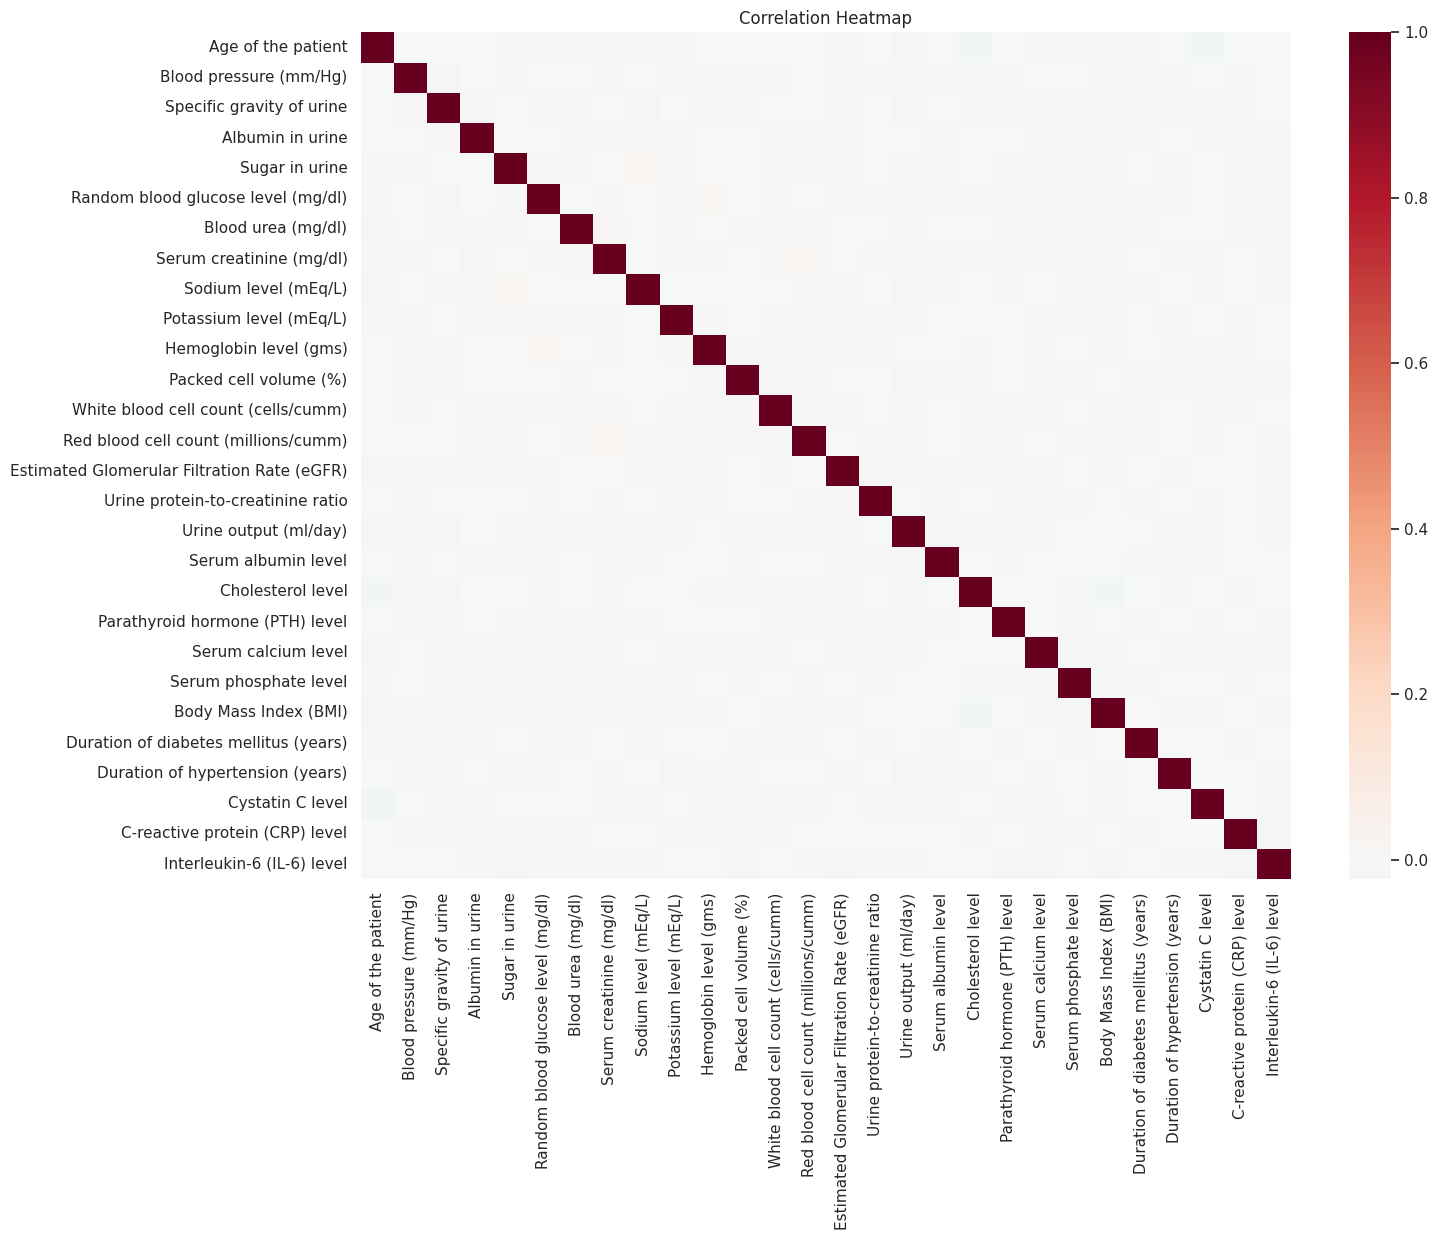

In [ ]:
plt.figure(figsize=(15, 11))

sns.heatmap(
    df[num_cols].corr(),
    cmap="RdBu_r",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap")

plt.show()

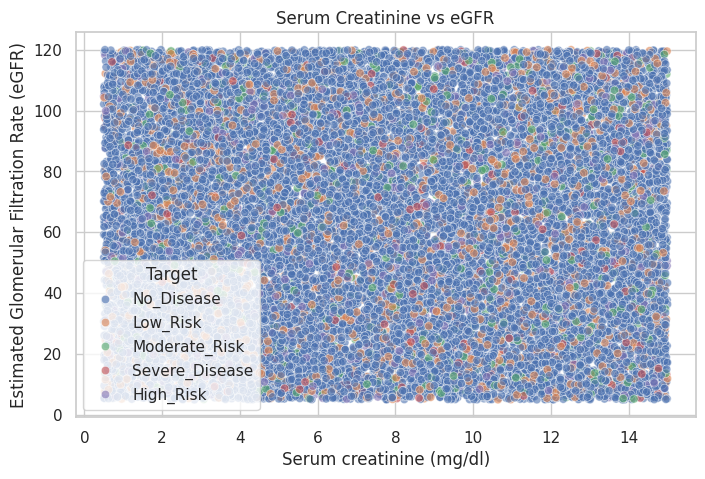

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Serum creatinine (mg/dl)",
    y="Estimated Glomerular Filtration Rate (eGFR)",
    hue="Target",
    alpha=0.6
)

plt.title("Serum Creatinine vs eGFR")
plt.show()

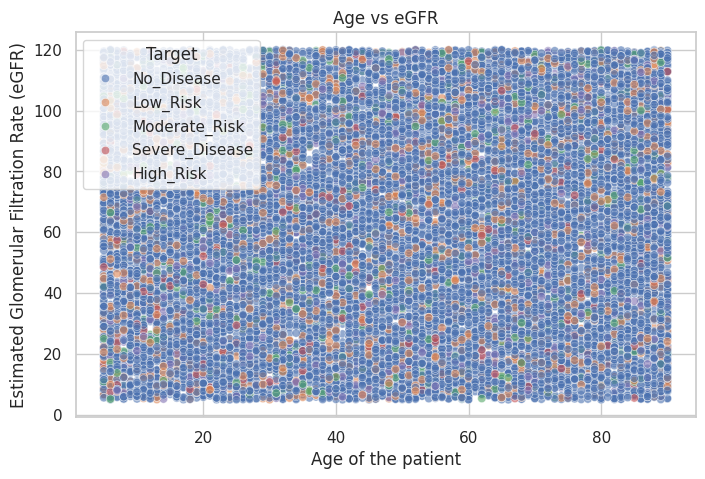

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Age of the patient",
    y="Estimated Glomerular Filtration Rate (eGFR)",
    hue="Target",
    alpha=0.6
)

plt.title("Age vs eGFR")
plt.show()

In [ ]:
clean = df.copy()

print("Rows before cleaning:", len(clean))

# Remove duplicate rows
clean = clean.drop_duplicates()

# Remove temporary target code
if "Target_Code" in clean.columns:
    clean = clean.drop(columns=["Target_Code"])

print("Rows after cleaning:", len(clean))

print(
    "Missing values:",
    clean.isna().sum().sum()
)

print(
    "Duplicate rows:",
    clean.duplicated().sum()
)

Rows before cleaning: 20538
Rows after cleaning: 20538
Missing values: 0
Duplicate rows: 0


In [ ]:
clean.to_csv(
    "kidney_clean.csv",
    index=False
)

print(
    "Saved kidney_clean.csv with shape:",
    clean.shape
)

Saved kidney_clean.csv with shape: (20538, 43)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("kidney_clean.csv")

print(df.shape)
print(df.head())

(20538, 43)
   Age of the patient  Blood pressure (mm/Hg)  Specific gravity of urine  Albumin in urine  Sugar in urine  \
0                  54                     167                      1.023                 1               4   
1                  42                     127                      1.023                 3               2   
2                  38                     148                      1.016                 0               0   
3                   7                      98                      1.017                 4               0   
4                  67                     174                      1.015                 1               1   

  Red blood cells in urine Pus cells in urine Pus cell clumps in urine Bacteria in urine  \
0                   normal           abnormal              not present       not present   
1                   normal             normal              not present           present   
2                 abnormal             normal      

In [ ]:
target_map = {
    "No_Disease": 0,
    "Low_Risk": 1,
    "Moderate_Risk": 2,
    "High_Risk": 3,
    "Severe_Disease": 4
}

df["Target_Code"] = df["Target"].map(target_map)

print(df["Target_Code"].value_counts().sort_index())

Target_Code
0    16432
1     2054
2      821
3      821
4      410
Name: count, dtype: int64


In [ ]:
fe = df.copy()

# Blood urea / creatinine ratio
fe["BUN_Creatinine_Ratio"] = (
    fe["Blood urea (mg/dl)"] /
    fe["Serum creatinine (mg/dl)"]
)

# Protein / creatinine ratio is already available,
# so we do not duplicate it.

# Duration of diabetes + hypertension
fe["Total_Comorbidity_Duration"] = (
    fe["Duration of diabetes mellitus (years)"] +
    fe["Duration of hypertension (years)"]
)

# Count of major comorbidity indicators
fe["Comorbidity_Count"] = (
    (fe["Hypertension (yes/no)"] == "yes").astype(int) +
    (fe["Diabetes mellitus (yes/no)"] == "yes").astype(int) +
    (fe["Coronary artery disease (yes/no)"] == "yes").astype(int)
)

# Kidney-related risk indicators
fe["Kidney_Risk_Flag_Count"] = (
    (fe["Albumin in urine"] > 0).astype(int) +
    (fe["Sugar in urine"] > 0).astype(int) +
    (fe["Pedal edema (yes/no)"] == "yes").astype(int) +
    (fe["Anemia (yes/no)"] == "yes").astype(int)
)

# Inflammation index
fe["Inflammation_Index"] = (
    fe["C-reactive protein (CRP) level"] +
    fe["Interleukin-6 (IL-6) level"]
)

# Electrolyte ratio
fe["Sodium_Potassium_Ratio"] = (
    fe["Sodium level (mEq/L)"] /
    fe["Potassium level (mEq/L)"]
)

print(
    fe[
        [
            "BUN_Creatinine_Ratio",
            "Total_Comorbidity_Duration",
            "Comorbidity_Count",
            "Kidney_Risk_Flag_Count",
            "Inflammation_Index",
            "Sodium_Potassium_Ratio"
        ]
    ].head()
)

   BUN_Creatinine_Ratio  Total_Comorbidity_Duration  Comorbidity_Count  Kidney_Risk_Flag_Count  \
0             22.397532                          20                  2                       2   
1             13.704075                          16                  1                       4   
2             20.352125                          34                  1                       1   
3             11.469890                          27                  1                       2   
4             65.511163                          46                  0                       4   

   Inflammation_Index  Sodium_Potassium_Ratio  
0               15.11               23.286829  
1               17.60               22.009402  
2               17.84               37.684854  
3               20.93               26.452304  
4                8.21               29.508105  


In [ ]:
fe["Age_Group"] = pd.cut(
    fe["Age of the patient"],
    bins=[0, 30, 45, 60, 75, 120],
    labels=[
        "Young",
        "Adult",
        "Middle_Age",
        "Senior",
        "Elderly"
    ]
)

print(fe["Age_Group"].value_counts())

Age_Group
Young         6208
Adult         3624
Elderly       3588
Senior        3564
Middle_Age    3554
Name: count, dtype: int64


In [ ]:
fe["BMI_Category"] = pd.cut(
    fe["Body Mass Index (BMI)"],
    bins=[0, 18.5, 25, 30, 100],
    labels=[
        "Underweight",
        "Normal",
        "Overweight",
        "Obese"
    ]
)

print(fe["BMI_Category"].value_counts())

BMI_Category
Obese          8196
Normal         5275
Overweight     4165
Underweight    2902
Name: count, dtype: int64


In [ ]:
fe["eGFR_Band"] = pd.cut(
    fe["Estimated Glomerular Filtration Rate (eGFR)"],
    bins=[-np.inf, 15, 30, 60, 90, np.inf],
    labels=[
        "Very_Low",
        "Low",
        "Moderate",
        "Near_Normal",
        "Normal_High"
    ]
)

print(fe["eGFR_Band"].value_counts())

eGFR_Band
Normal_High    5353
Moderate       5346
Near_Normal    5280
Low            2712
Very_Low       1847
Name: count, dtype: int64


In [ ]:
skew_cols = [
    "Blood urea (mg/dl)",
    "Serum creatinine (mg/dl)",
    "Urine protein-to-creatinine ratio",
    "White blood cell count (cells/cumm)",
    "Parathyroid hormone (PTH) level",
    "C-reactive protein (CRP) level",
    "Interleukin-6 (IL-6) level"
]

for col in skew_cols:
    if (fe[col] >= 0).all():
        fe[col + "_Log"] = np.log1p(fe[col])

print(fe.head())

   Age of the patient  Blood pressure (mm/Hg)  Specific gravity of urine  Albumin in urine  Sugar in urine  \
0                  54                     167                      1.023                 1               4   
1                  42                     127                      1.023                 3               2   
2                  38                     148                      1.016                 0               0   
3                   7                      98                      1.017                 4               0   
4                  67                     174                      1.015                 1               1   

  Red blood cells in urine Pus cells in urine Pus cell clumps in urine Bacteria in urine  \
0                   normal           abnormal              not present       not present   
1                   normal             normal              not present           present   
2                 abnormal             normal              not 

In [ ]:
for col in skew_cols:

    print(
        f"{col:50s}",
        "Original =",
        round(fe[col].skew(), 2),
        "| Log =",
        round(fe[col + "_Log"].skew(), 2)
    )

Blood urea (mg/dl)                                 Original = -0.01 | Log = -1.07
Serum creatinine (mg/dl)                           Original = -0.01 | Log = -0.81
Urine protein-to-creatinine ratio                  Original = 0.01 | Log = -0.53
White blood cell count (cells/cumm)                Original = -0.01 | Log = -0.55
Parathyroid hormone (PTH) level                    Original = -0.02 | Log = -0.66
C-reactive protein (CRP) level                     Original = -0.01 | Log = -0.79
Interleukin-6 (IL-6) level                         Original = 0.01 | Log = -0.78


In [ ]:
new_features = [
    "BUN_Creatinine_Ratio",
    "Total_Comorbidity_Duration",
    "Comorbidity_Count",
    "Kidney_Risk_Flag_Count",
    "Inflammation_Index",
    "Sodium_Potassium_Ratio"
]

print(
    fe[new_features]
    .corrwith(fe["Target_Code"])
    .sort_values(key=abs, ascending=False)
    .round(3)
)

BUN_Creatinine_Ratio         -0.009
Comorbidity_Count            -0.006
Sodium_Potassium_Ratio        0.005
Kidney_Risk_Flag_Count       -0.001
Total_Comorbidity_Duration   -0.000
Inflammation_Index           -0.000
dtype: float64


In [ ]:
categorical_features = [
    "Red blood cells in urine",
    "Pus cells in urine",
    "Pus cell clumps in urine",
    "Bacteria in urine",
    "Hypertension (yes/no)",
    "Diabetes mellitus (yes/no)",
    "Coronary artery disease (yes/no)",
    "Appetite (good/poor)",
    "Pedal edema (yes/no)",
    "Anemia (yes/no)",
    "Family history of chronic kidney disease",
    "Smoking status",
    "Physical activity level",
    "Urinary sediment microscopy results"
]

fe_encoded = pd.get_dummies(
    fe,
    columns=categorical_features,
    dtype=int
)

print(fe_encoded.shape)
print(fe_encoded.head())

(20538, 75)
   Age of the patient  Blood pressure (mm/Hg)  Specific gravity of urine  Albumin in urine  Sugar in urine  \
0                  54                     167                      1.023                 1               4   
1                  42                     127                      1.023                 3               2   
2                  38                     148                      1.016                 0               0   
3                   7                      98                      1.017                 4               0   
4                  67                     174                      1.015                 1               1   

   Random blood glucose level (mg/dl)  Blood urea (mg/dl)  Serum creatinine (mg/dl)  Sodium level (mEq/L)  \
0                                  96          169.101369                      7.55            146.068410   
1                                  73          183.223479                     13.37            123.501427   


In [ ]:
categorical_features = [
    "Red blood cells in urine",
    "Pus cells in urine",
    "Pus cell clumps in urine",
    "Bacteria in urine",
    "Hypertension (yes/no)",
    "Diabetes mellitus (yes/no)",
    "Coronary artery disease (yes/no)",
    "Appetite (good/poor)",
    "Pedal edema (yes/no)",
    "Anemia (yes/no)",
    "Family history of chronic kidney disease",
    "Smoking status",
    "Physical activity level",
    "Urinary sediment microscopy results"
]

fe_encoded = pd.get_dummies(
    fe,
    columns=categorical_features,
    dtype=int
)

print(fe_encoded.shape)
print(fe_encoded.head())

(20538, 75)
   Age of the patient  Blood pressure (mm/Hg)  Specific gravity of urine  Albumin in urine  Sugar in urine  \
0                  54                     167                      1.023                 1               4   
1                  42                     127                      1.023                 3               2   
2                  38                     148                      1.016                 0               0   
3                   7                      98                      1.017                 4               0   
4                  67                     174                      1.015                 1               1   

   Random blood glucose level (mg/dl)  Blood urea (mg/dl)  Serum creatinine (mg/dl)  Sodium level (mEq/L)  \
0                                  96          169.101369                      7.55            146.068410   
1                                  73          183.223479                     13.37            123.501427   


In [ ]:
numeric_fe = fe_encoded.select_dtypes(
    include="number"
)

corr_target = (
    numeric_fe
    .corr()["Target_Code"]
    .drop("Target_Code")
    .sort_values(
        key=abs,
        ascending=False
    )
)

print(corr_target.round(3))

Pus cells in urine_abnormal             0.021
Pus cells in urine_normal              -0.021
Specific gravity of urine              -0.017
Age of the patient                     -0.016
Serum creatinine (mg/dl)                0.014
                                        ...  
Pus cell clumps in urine_not present   -0.000
Parathyroid hormone (PTH) level         0.000
Red blood cell count (millions/cumm)    0.000
Inflammation_Index                     -0.000
Cholesterol level                      -0.000
Name: Target_Code, Length: 70, dtype: float64


In [ ]:
corr_feat = numeric_fe.drop(
    columns=["Target_Code"]
).corr().abs()

upper = corr_feat.where(
    np.triu(
        np.ones(corr_feat.shape),
        k=1
    ).astype(bool)
)

pairs = (
    upper
    .stack()
    .sort_values(ascending=False)
)

print("Feature pairs with correlation above 0.85:")

print(
    pairs[pairs > 0.85]
    .round(3)
)

Feature pairs with correlation above 0.85:
Urinary sediment microscopy results_abnormal  Urinary sediment microscopy results_normal      1.000
Coronary artery disease (yes/no)_no           Coronary artery disease (yes/no)_yes            1.000
Diabetes mellitus (yes/no)_no                 Diabetes mellitus (yes/no)_yes                  1.000
Bacteria in urine_not present                 Bacteria in urine_present                       1.000
Smoking status_no                             Smoking status_yes                              1.000
Family history of chronic kidney disease_no   Family history of chronic kidney disease_yes    1.000
Red blood cells in urine_abnormal             Red blood cells in urine_normal                 1.000
Pus cells in urine_abnormal                   Pus cells in urine_normal                       1.000
Hypertension (yes/no)_no                      Hypertension (yes/no)_yes                       1.000
Pus cell clumps in urine_not present          Pus cell cl

In [ ]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# 1. Separate X and y
# -----------------------------

X = fe_encoded.drop(
    columns=["Target", "Target_Code"],
    errors="ignore"
)

y = fe_encoded["Target_Code"]

print("Before encoding:")
print("X shape:", X.shape)
print("Object columns:", X.select_dtypes(include="object").columns.tolist())


# -----------------------------
# 2. Encode remaining text columns
# -----------------------------

X = pd.get_dummies(
    X,
    dtype=int
)

print("\nAfter encoding:")
print("X shape:", X.shape)
print("Missing values in X:", X.isna().sum().sum())
print("Missing values in y:", y.isna().sum())


# -----------------------------
# 3. Train Random Forest
# -----------------------------

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf.fit(X, y)


# -----------------------------
# 4. Feature Importance
# -----------------------------

importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nTop 20 Important Features:")
print(importance.head(20).round(4))

Before encoding:
X shape: (20538, 73)
Object columns: []

After encoding:
X shape: (20538, 84)
Missing values in X: 0
Missing values in y: 0

Top 20 Important Features:
Urine output (ml/day)                          0.0253
Serum calcium level                            0.0252
Serum phosphate level                          0.0248
Random blood glucose level (mg/dl)             0.0246
Estimated Glomerular Filtration Rate (eGFR)    0.0246
Cystatin C level                               0.0246
Cholesterol level                              0.0246
Sodium level (mEq/L)                           0.0243
Potassium level (mEq/L)                        0.0242
Serum albumin level                            0.0240
Blood pressure (mm/Hg)                         0.0240
Hemoglobin level (gms)                         0.0237
Sodium_Potassium_Ratio                         0.0234
Body Mass Index (BMI)                          0.0234
Inflammation_Index                             0.0231
Parathyroid hormone (

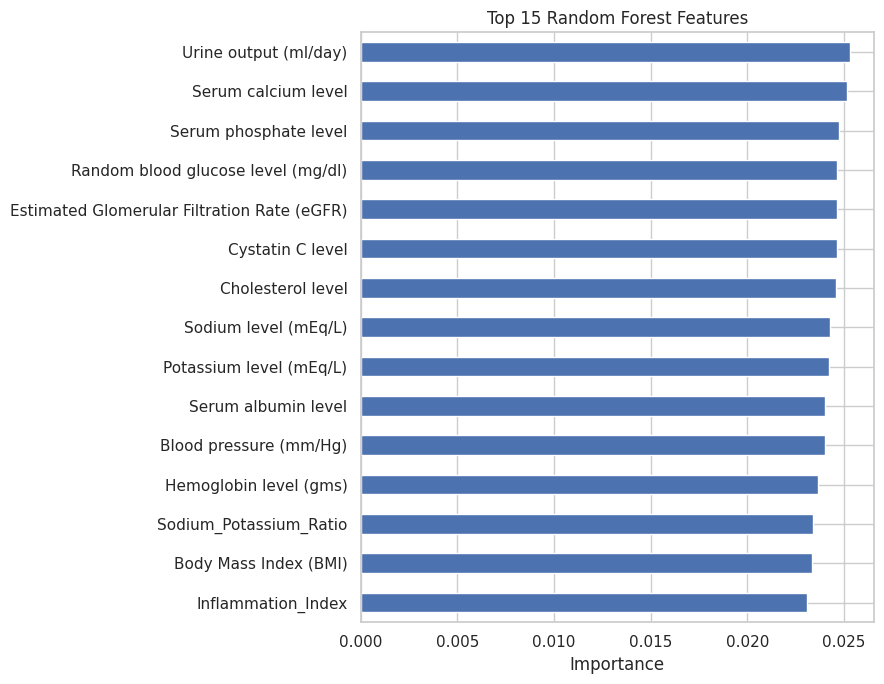

In [ ]:
# #40 Random Forest Feature Importance Plot

plt.figure(figsize=(9, 7))

importance.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Random Forest Features")
plt.xlabel("Importance")

plt.tight_layout()
plt.show()

In [ ]:
# #41 Permutation Importance

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
import pandas as pd

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

# Train Random Forest
rf_perm = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_perm.fit(X_train, y_train)

# Permutation Importance
perm = permutation_importance(
    rf_perm,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="accuracy",
    n_jobs=-1
)

# Create importance series
perm_imp = pd.Series(
    perm.importances_mean,
    index=X.columns
).sort_values(ascending=False)

print("\nPermutation Importance:")
print(perm_imp.head(15).round(4))

Train shape: (15403, 84)
Test shape: (5135, 84)

Permutation Importance:
Age of the patient                             0.0
Blood pressure (mm/Hg)                         0.0
Specific gravity of urine                      0.0
Albumin in urine                               0.0
Sugar in urine                                 0.0
Random blood glucose level (mg/dl)             0.0
Blood urea (mg/dl)                             0.0
Serum creatinine (mg/dl)                       0.0
Sodium level (mEq/L)                           0.0
Potassium level (mEq/L)                        0.0
Hemoglobin level (gms)                         0.0
Packed cell volume (%)                         0.0
White blood cell count (cells/cumm)            0.0
Red blood cell count (millions/cumm)           0.0
Estimated Glomerular Filtration Rate (eGFR)    0.0
dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

X = fe_encoded.drop(
    columns=[
        "Target",
        "Target_Code"
    ]
)

y = fe_encoded["Target_Code"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (15403, 73)
X_test : (5135, 73)
y_train: (15403,)
y_test : (5135,)


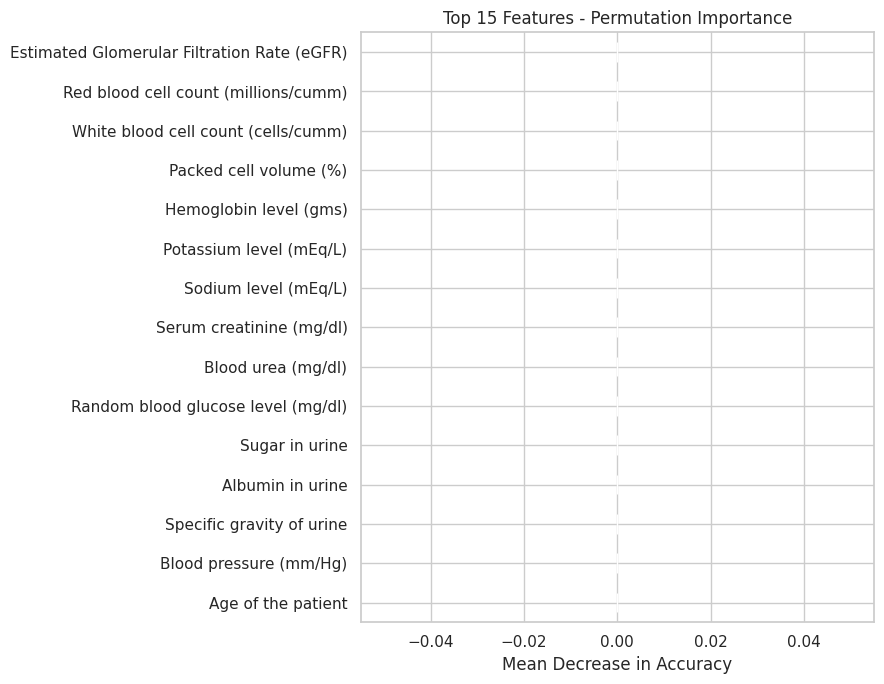

In [ ]:
# #42 Permutation Importance Plot

plt.figure(figsize=(9, 7))

perm_imp.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Features - Permutation Importance")
plt.xlabel("Mean Decrease in Accuracy")

plt.tight_layout()
plt.show()

In [ ]:
# #43 Feature Ideas Check

feature_ideas = [
    "BUN_Creatinine_Ratio",
    "Comorbidity_Count",
    "Kidney_Risk_Flag_Count",
    "Inflammation_Index",
    "Sodium_Potassium_Ratio"
]

for feature in feature_ideas:
    if feature in fe_encoded.columns:
        correlation = fe_encoded[feature].corr(
            fe_encoded["Target_Code"]
        )

        print(
            f"{feature}: {correlation:.3f}"
        )

BUN_Creatinine_Ratio: -0.009
Comorbidity_Count: -0.006
Kidney_Risk_Flag_Count: -0.001
Inflammation_Index: -0.000
Sodium_Potassium_Ratio: 0.005


In [ ]:
# #44 Kidney Risk Summary

risk_summary = df.groupby("Target").agg(
    Patient_Count=("Target", "count"),
    Average_Age=("Age of the patient", "mean"),
    Average_Urea=("Blood urea (mg/dl)", "mean"),
    Average_Creatinine=("Serum creatinine (mg/dl)", "mean"),
    Average_eGFR=("Estimated Glomerular Filtration Rate (eGFR)", "mean")
).round(2)

print(risk_summary)

                Patient_Count  Average_Age  Average_Urea  Average_Creatinine  Average_eGFR
Target                                                                                    
High_Risk                 821        46.31        101.68                7.78         63.06
Low_Risk                 2054        47.10        104.31                7.82         63.07
Moderate_Risk             821        46.43        105.98                8.03         64.05
No_Disease              16432        47.67        104.15                7.76         62.02
Severe_Disease            410        46.30        101.90                8.12         61.17


In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df3 = pd.read_csv("kidney_disease_dataset.csv")

print("Dataset Shape:", df3.shape)
print("Missing Values:", df3.isna().sum().sum())

Dataset Shape: (20538, 43)
Missing Values: 0


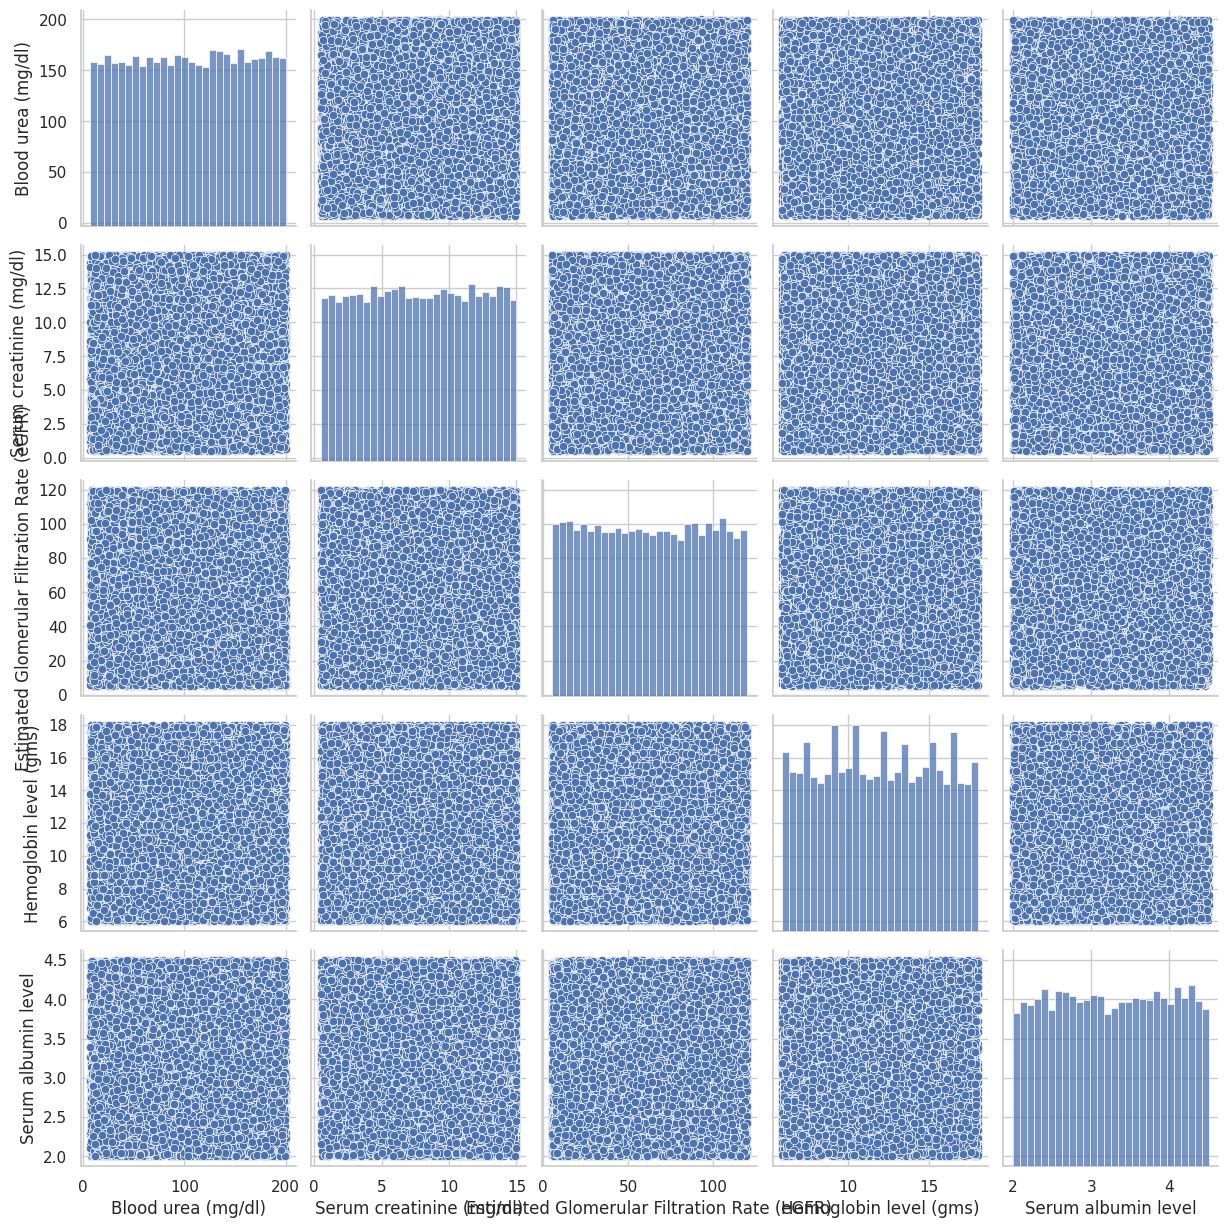

In [ ]:
# #46 Pair Plot

pair_columns = [
    "Blood urea (mg/dl)",
    "Serum creatinine (mg/dl)",
    "Estimated Glomerular Filtration Rate (eGFR)",
    "Hemoglobin level (gms)",
    "Serum albumin level"
]

sns.pairplot(
    df3[pair_columns],
    diag_kind="hist"
)

plt.show()

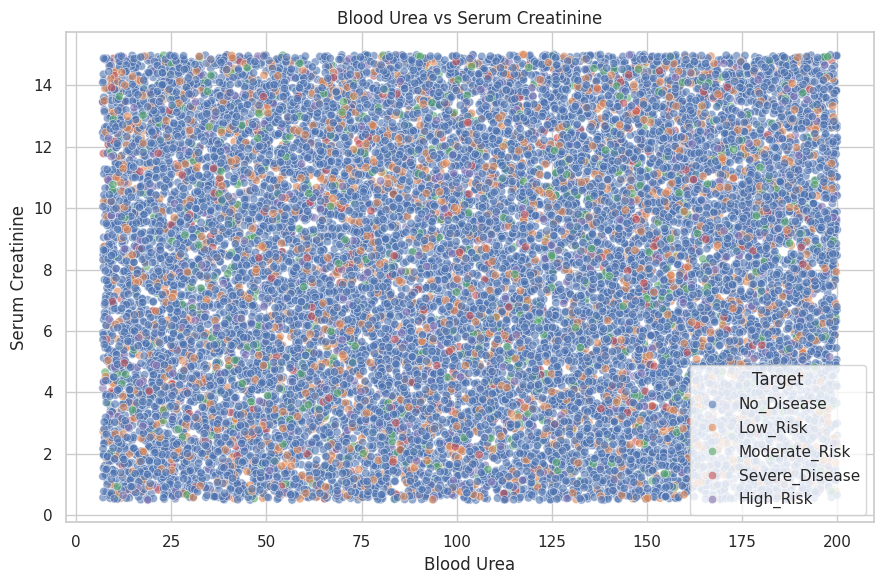

In [ ]:
# #47 Scatter Plot

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df3,
    x="Blood urea (mg/dl)",
    y="Serum creatinine (mg/dl)",
    hue="Target",
    alpha=0.6
)

plt.title("Blood Urea vs Serum Creatinine")
plt.xlabel("Blood Urea")
plt.ylabel("Serum Creatinine")

plt.tight_layout()
plt.show()

In [ ]:
# #48 Risk Group Summary

summary = df3.groupby("Target").agg(
    Count=("Target", "count"),
    Mean_Age=("Age of the patient", "mean"),
    Mean_Urea=("Blood urea (mg/dl)", "mean"),
    Mean_Creatinine=("Serum creatinine (mg/dl)", "mean"),
    Mean_eGFR=("Estimated Glomerular Filtration Rate (eGFR)", "mean"),
    Mean_Hemoglobin=("Hemoglobin level (gms)", "mean")
).round(2)

print(summary)

                Count  Mean_Age  Mean_Urea  Mean_Creatinine  Mean_eGFR  Mean_Hemoglobin
Target                                                                                 
High_Risk         821     46.31     101.68             7.78      63.06            12.07
Low_Risk         2054     47.10     104.31             7.82      63.07            11.83
Moderate_Risk     821     46.43     105.98             8.03      64.05            11.83
No_Disease      16432     47.67     104.15             7.76      62.02            11.98
Severe_Disease    410     46.30     101.90             8.12      61.17            11.92


In [ ]:
# #49 Age Groups

df3["Age_Group"] = pd.cut(
    df3["Age of the patient"],
    bins=[0, 30, 50, 70, 100],
    labels=[
        "Young",
        "Middle_Age",
        "Older",
        "Senior"
    ]
)

print(df3["Age_Group"].value_counts())

Age_Group
Young         6208
Older         4789
Middle_Age    4784
Senior        4757
Name: count, dtype: int64


Target      High_Risk  Low_Risk  Moderate_Risk  No_Disease  Severe_Disease
Age_Group                                                                 
Young            7.76      7.82           8.32        7.81            8.54
Middle_Age       7.91      7.91           8.32        7.72            8.44
Older            7.83      7.41           7.81        7.69            7.86
Senior           7.64      8.15           7.51        7.79            7.42


/tmp/ipykernel_1308/3942696189.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = pd.pivot_table(


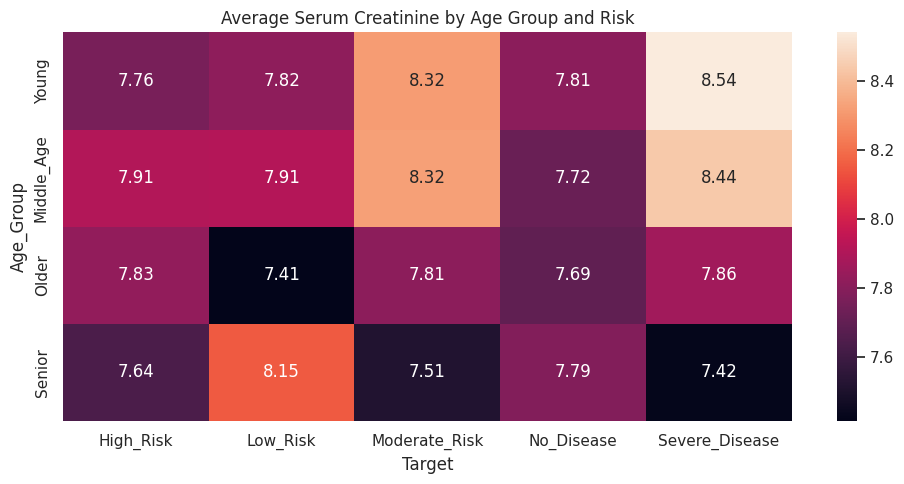

In [ ]:
# #50 Pivot Table + Heatmap

pivot = pd.pivot_table(
    df3,
    index="Age_Group",
    columns="Target",
    values="Serum creatinine (mg/dl)",
    aggfunc="mean"
)

print(pivot.round(2))

plt.figure(figsize=(10, 5))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".2f"
)

plt.title(
    "Average Serum Creatinine by Age Group and Risk"
)

plt.tight_layout()
plt.show()

In [ ]:
# #51 VIF

from sklearn.linear_model import LinearRegression

vif_columns = [
    "Age of the patient",
    "Blood pressure (mm/Hg)",
    "Blood urea (mg/dl)",
    "Serum creatinine (mg/dl)",
    "Estimated Glomerular Filtration Rate (eGFR)",
    "Hemoglobin level (gms)",
    "Serum albumin level",
    "Cystatin C level"
]

vif_values = {}

for column in vif_columns:

    other_columns = [
        c for c in vif_columns
        if c != column
    ]

    model = LinearRegression()

    model.fit(
        df3[other_columns],
        df3[column]
    )

    r2 = model.score(
        df3[other_columns],
        df3[column]
    )

    vif_values[column] = 1 / (1 - r2)

print(
    pd.Series(vif_values)
    .sort_values(ascending=False)
    .round(2)
)

Age of the patient                             1.0
Cystatin C level                               1.0
Serum creatinine (mg/dl)                       1.0
Serum albumin level                            1.0
Estimated Glomerular Filtration Rate (eGFR)    1.0
Blood urea (mg/dl)                             1.0
Hemoglobin level (gms)                         1.0
Blood pressure (mm/Hg)                         1.0
dtype: float64


In [ ]:
# #51 VIF

from sklearn.linear_model import LinearRegression

vif_columns = [
    "Age of the patient",
    "Blood pressure (mm/Hg)",
    "Blood urea (mg/dl)",
    "Serum creatinine (mg/dl)",
    "Estimated Glomerular Filtration Rate (eGFR)",
    "Hemoglobin level (gms)",
    "Serum albumin level",
    "Cystatin C level"
]

vif_values = {}

for column in vif_columns:

    other_columns = [
        c for c in vif_columns
        if c != column
    ]

    model = LinearRegression()

    model.fit(
        df3[other_columns],
        df3[column]
    )

    r2 = model.score(
        df3[other_columns],
        df3[column]
    )

    vif_values[column] = 1 / (1 - r2)

print(
    pd.Series(vif_values)
    .sort_values(ascending=False)
    .round(2)
)

Age of the patient                             1.0
Cystatin C level                               1.0
Serum creatinine (mg/dl)                       1.0
Serum albumin level                            1.0
Estimated Glomerular Filtration Rate (eGFR)    1.0
Blood urea (mg/dl)                             1.0
Hemoglobin level (gms)                         1.0
Blood pressure (mm/Hg)                         1.0
dtype: float64


In [ ]:
# #53 Standardization

from sklearn.preprocessing import StandardScaler

pca_columns = [
    "Age of the patient",
    "Blood pressure (mm/Hg)",
    "Blood urea (mg/dl)",
    "Serum creatinine (mg/dl)",
    "Estimated Glomerular Filtration Rate (eGFR)",
    "Hemoglobin level (gms)",
    "Serum albumin level",
    "Cystatin C level"
]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    df3[pca_columns]
)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (20538, 8)


In [ ]:
# #54 PCA

from sklearn.decomposition import PCA

pca = PCA()

pca.fit(X_scaled)

explained_variance = (
    pca.explained_variance_ratio_ * 100
)

for i, value in enumerate(
    explained_variance,
    start=1
):
    print(
        f"PC{i}: {value:.2f}%"
    )

PC1: 12.95%
PC2: 12.76%
PC3: 12.67%
PC4: 12.49%
PC5: 12.42%
PC6: 12.37%
PC7: 12.25%
PC8: 12.09%


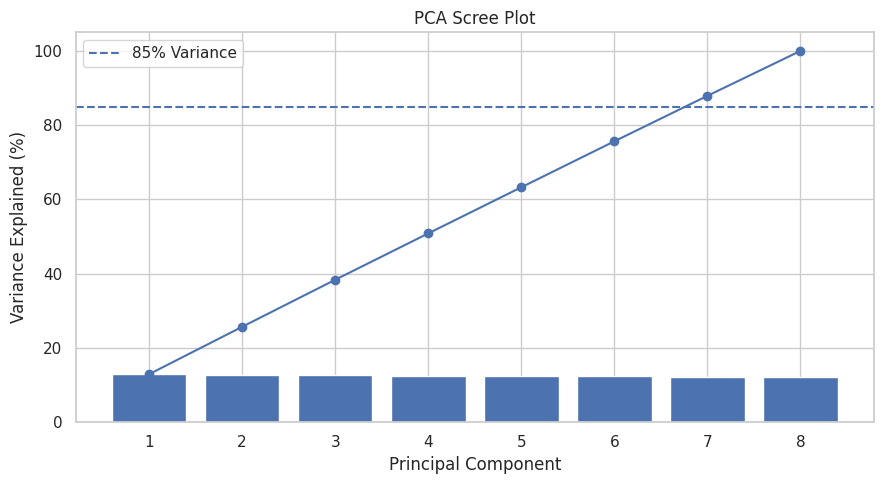

In [ ]:
# #55 PCA Scree Plot

components = range(
    1,
    len(explained_variance) + 1
)

cumulative = np.cumsum(
    explained_variance
)

plt.figure(figsize=(9, 5))

plt.bar(
    components,
    explained_variance
)

plt.plot(
    components,
    cumulative,
    marker="o"
)

plt.axhline(
    85,
    linestyle="--",
    label="85% Variance"
)

plt.xlabel("Principal Component")
plt.ylabel("Variance Explained (%)")
plt.title("PCA Scree Plot")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# #56 PCA Loadings

pca_2 = PCA(
    n_components=2
)

pca_2.fit(X_scaled)

loadings = pd.DataFrame(
    pca_2.components_.T,
    index=pca_columns,
    columns=["PC1", "PC2"]
)

print(
    loadings.round(3)
)

                                               PC1    PC2
Age of the patient                          -0.554  0.327
Blood pressure (mm/Hg)                      -0.107 -0.397
Blood urea (mg/dl)                          -0.159  0.579
Serum creatinine (mg/dl)                     0.325  0.516
Estimated Glomerular Filtration Rate (eGFR) -0.333 -0.053
Hemoglobin level (gms)                       0.095 -0.092
Serum albumin level                         -0.351 -0.332
Cystatin C level                             0.555 -0.113


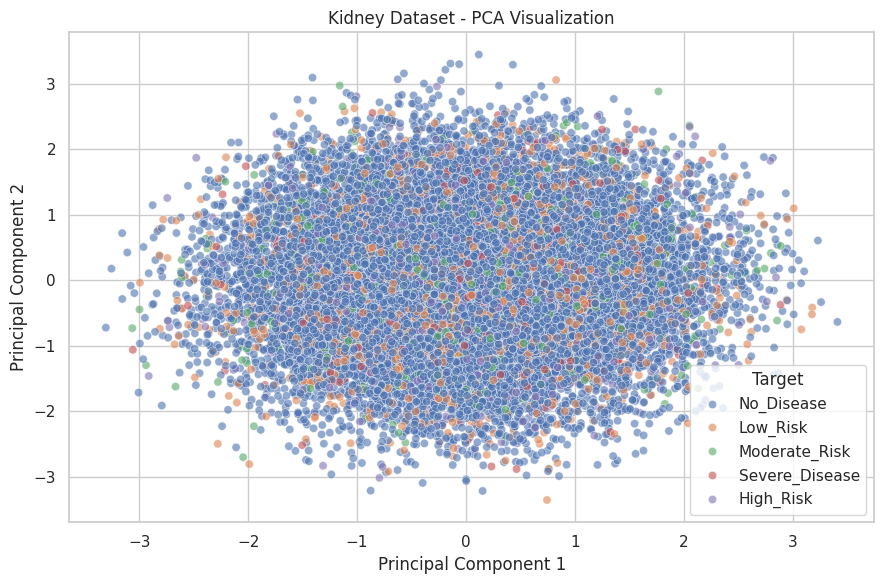

In [ ]:
# #57 PCA Visualization

pca_result = PCA(
    n_components=2
).fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=pca_result[:, 0],
    y=pca_result[:, 1],
    hue=df3["Target"],
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title(
    "Kidney Dataset - PCA Visualization"
)

plt.tight_layout()
plt.show()

In [ ]:
# #58 K-Means Clustering

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_columns = [
    "Blood urea (mg/dl)",
    "Serum creatinine (mg/dl)",
    "Estimated Glomerular Filtration Rate (eGFR)",
    "Hemoglobin level (gms)",
    "Serum albumin level"
]

X_cluster = StandardScaler().fit_transform(
    df3[cluster_columns]
)

for k in range(2, 6):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(
        X_cluster
    )

    score = silhouette_score(
        X_cluster,
        labels
    )

    print(
        f"K = {k} | Silhouette Score = {score:.3f}"
    )

K = 2 | Silhouette Score = 0.149
K = 3 | Silhouette Score = 0.137
K = 4 | Silhouette Score = 0.143
K = 5 | Silhouette Score = 0.147


In [ ]:
# #59 Cluster Profile

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df3["Cluster"] = kmeans.fit_predict(
    X_cluster
)

cluster_profile = df3.groupby(
    "Cluster"
).agg(
    Patients=("Target", "count"),
    Urea=("Blood urea (mg/dl)", "mean"),
    Creatinine=("Serum creatinine (mg/dl)", "mean"),
    eGFR=("Estimated Glomerular Filtration Rate (eGFR)", "mean"),
    Hemoglobin=("Hemoglobin level (gms)", "mean")
).round(2)

print(cluster_profile)

         Patients    Urea  Creatinine   eGFR  Hemoglobin
Cluster                                                 
0            6392  104.36        7.94  60.09        9.75
1            7561  103.78        7.70  64.16       15.64
2            6585  104.20        7.73  62.09        9.88


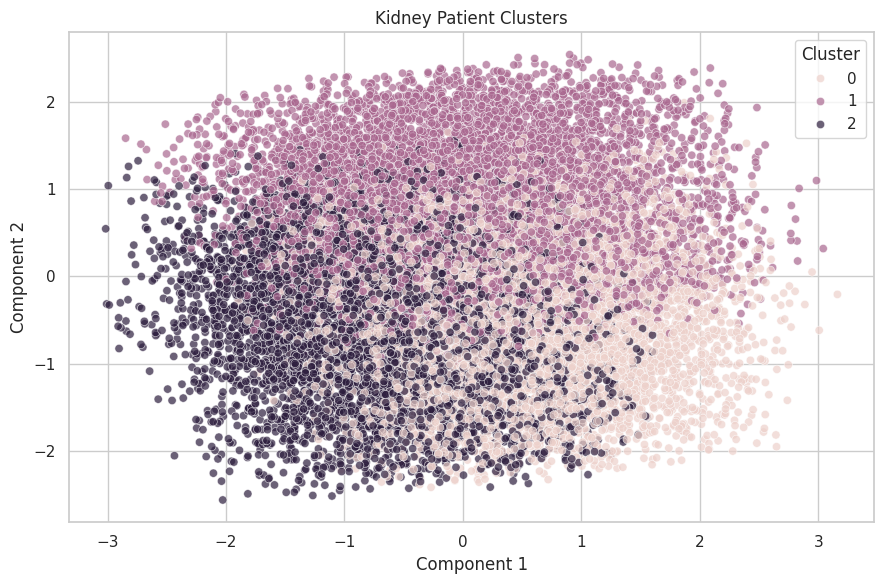

In [ ]:
# #60 Cluster Visualization

cluster_pca = PCA(
    n_components=2
).fit_transform(X_cluster)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=cluster_pca[:, 0],
    y=cluster_pca[:, 1],
    hue=df3["Cluster"],
    alpha=0.7
)

plt.xlabel("Component 1")
plt.ylabel("Component 2")

plt.title(
    "Kidney Patient Clusters"
)

plt.tight_layout()
plt.show()

In [ ]:
# #61 Automated EDA Report

def kidney_eda_report(data):

    print("=" * 60)
    print("KIDNEY DISEASE EDA REPORT")
    print("=" * 60)

    print("\nDataset Shape:")
    print(data.shape)

    print("\nMissing Values:")
    print(data.isna().sum().sum())

    print("\nDuplicate Rows:")
    print(data.duplicated().sum())

    print("\nTarget Distribution:")
    print(data["Target"].value_counts())

    print("\nNumerical Columns:")
    print(
        data.select_dtypes(
            include=np.number
        ).columns.tolist()
    )

    print("\nCategorical Columns:")
    print(
        data.select_dtypes(
            include="object"
        ).columns.tolist()
    )


kidney_eda_report(df3)

KIDNEY DISEASE EDA REPORT

Dataset Shape:
(20538, 45)

Missing Values:
0

Duplicate Rows:
0

Target Distribution:
Target
No_Disease        16432
Low_Risk           2054
Moderate_Risk       821
High_Risk           821
Severe_Disease      410
Name: count, dtype: int64

Numerical Columns:
['Age of the patient', 'Blood pressure (mm/Hg)', 'Specific gravity of urine', 'Albumin in urine', 'Sugar in urine', 'Random blood glucose level (mg/dl)', 'Blood urea (mg/dl)', 'Serum creatinine (mg/dl)', 'Sodium level (mEq/L)', 'Potassium level (mEq/L)', 'Hemoglobin level (gms)', 'Packed cell volume (%)', 'White blood cell count (cells/cumm)', 'Red blood cell count (millions/cumm)', 'Estimated Glomerular Filtration Rate (eGFR)', 'Urine protein-to-creatinine ratio', 'Urine output (ml/day)', 'Serum albumin level', 'Cholesterol level', 'Parathyroid hormone (PTH) level', 'Serum calcium level', 'Serum phosphate level', 'Body Mass Index (BMI)', 'Duration of diabetes mellitus (years)', 'Duration of hypertension

In [ ]:
# #62 ML Ready Dataset

ml_data = df3.copy()

# Remove cluster column
ml_data = ml_data.drop(
    columns=["Cluster"],
    errors="ignore"
)

# Separate target
y_ml = ml_data["Target"]

X_ml = ml_data.drop(
    columns=["Target"]
)

# Convert categorical features
X_ml = pd.get_dummies(
    X_ml,
    dtype=int
)

print("X shape:", X_ml.shape)
print("y shape:", y_ml.shape)

print(
    "\nRemaining object columns:",
    X_ml.select_dtypes(
        include="object"
    ).columns.tolist()
)

X shape: (20538, 61)
y shape: (20538,)

Remaining object columns: []


In [ ]:
# #63 Train Test Split

from sklearn.model_selection import train_test_split

X_train_ml, X_test_ml, y_train_ml, y_test_ml = train_test_split(
    X_ml,
    y_ml,
    test_size=0.25,
    random_state=42,
    stratify=y_ml
)

print(
    "Training data:",
    X_train_ml.shape
)

print(
    "Testing data:",
    X_test_ml.shape
)

Training data: (15403, 61)
Testing data: (5135, 61)


In [ ]:
# #64 Logistic Regression Baseline

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "logistic",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        )
    )
])

model.fit(
    X_train_ml,
    y_train_ml
)

predictions = model.predict(
    X_test_ml
)

accuracy = accuracy_score(
    y_test_ml,
    predictions
)

print(
    f"Accuracy: {accuracy:.4f}"
)

print("\nClassification Report:")
print(
    classification_report(
        y_test_ml,
        predictions
    )
)

Accuracy: 0.1326

Classification Report:
                precision    recall  f1-score   support

     High_Risk       0.04      0.24      0.07       205
      Low_Risk       0.10      0.15      0.12       514
 Moderate_Risk       0.04      0.22      0.06       205
    No_Disease       0.81      0.12      0.21      4108
Severe_Disease       0.02      0.26      0.04       103

      accuracy                           0.13      5135
     macro avg       0.20      0.20      0.10      5135
  weighted avg       0.66      0.13      0.18      5135



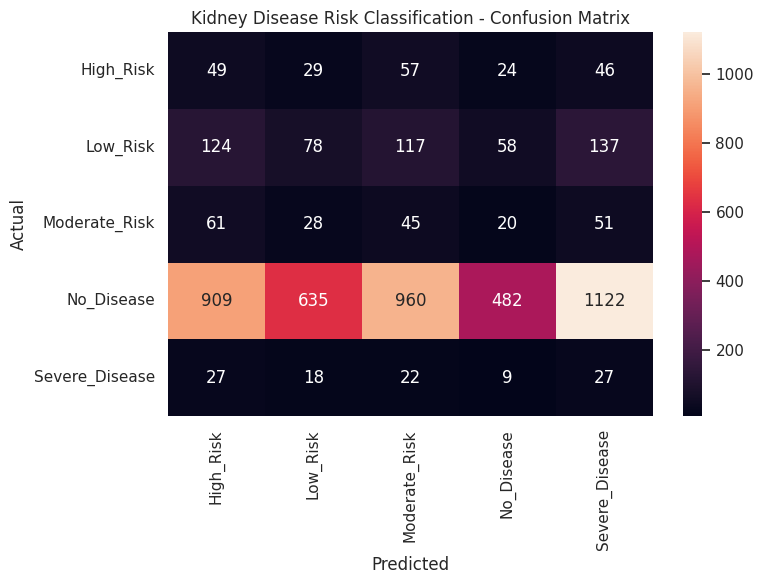

In [ ]:
# #65 Confusion Matrix

cm = confusion_matrix(
    y_test_ml,
    predictions
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=sorted(y_ml.unique()),
    yticklabels=sorted(y_ml.unique())
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "Kidney Disease Risk Classification - Confusion Matrix"
)

plt.tight_layout()
plt.show()